# Session 11: Optimizers and Learning-Rate Schedules, measured

Session 10 left one line of the training step unexplained: `optimizer.step()`. The gradient says *which way* each
weight should move. It does not say *how far*. Every method in this session is a rule for the distance, and this
notebook checks each rule on a real model and real data instead of trusting it.

| # | Assignment task | Section |
|---|---|---|
| 1 | Reproduce Adam by hand for one weight and five gradients, check every value against PyTorch | 1 |
| 2 | Disable bias correction, plot the first 20 steps both ways, report when the difference stops mattering | 2 |
| 3 | Log the update-to-weight ratio for every layer, find the step at which warmup stops changing it | 3 |
| 4 | Train the same model twice for a planned 300 steps (cosine, WSD), stop both at 200, report losses, pick one | 4 |
| 5 | Sweep the learning rate at widths 256, 512, 1024, mark the minima, give a value for width 4096 and a confidence | 5 |

Extra experiments (not required, added to understand *why*): why Adam's step is about $\eta$ and when it is not
(1d), L2 against decoupled weight decay measured (1e), optimizer memory measured on the GPU (1f), bias correction on a
real model (2c), the lesson's "19 times too large" first step checked tensor by tensor (3a), a deliberately planned
200-step cosine, a WSD branch and a constant-LR-plus-weight-averaging run at equal compute (4c), and the same width
sweep under muP (5e).

**Model:** the Llama-style decoder from Assignment 10 (RMSNorm, RoPE, SwiGLU), with an untied head so that muP can
give the head its own treatment. **Data:** TinyStories, GPT-2 BPE tokens. **Hardware:** Colab Pro, A100. The whole
notebook runs top to bottom in about 30 minutes; the last cell releases the Colab runtime so that no credits are
burned after it finishes.

### Words used throughout

| Term | Meaning | Typical value here |
|---|---|---|
| learning rate $\eta$ | converts a gradient into a distance | $10^{-3}$ |
| step / update | one call of `optimizer.step()`, the change $\Delta w$ it applies | |
| optimizer state | what the optimizer stores per weight between steps ($m$, $v$ for Adam) | 8 bytes per weight |
| EMA | exponential moving average, $a \leftarrow \beta a + (1-\beta)x$; remembers about $1/(1-\beta)$ values | |
| warmup | raising $\eta$ linearly from about 0 to its peak over the first $W$ steps | $W$ = 20 to 100 |
| schedule | the rule giving $\eta$ at every step | cosine, WSD |
| width | $d_{\text{model}}$, the size of the residual vector | 256 to 1,024 |
| nat | unit of the loss (natural log); a loss drop of 0.01 nats is a 1% better likelihood per token | |

## 0. Setup

Colab already has PyTorch, `huggingface_hub` and `pyarrow`; only the GPT-2 tokenizer (`tiktoken`) is installed.
The kernel is remote, so the model file is written on the Colab machine with `%%writefile`.

In [1]:
!pip -q install tiktoken

In [2]:
import math, time, json, os, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.backends.cuda.matmul.allow_tf32 = True     # fp32 matmuls (only in the small Section 1 checks) may use TF32
torch.backends.cudnn.allow_tf32 = True
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch version           : {torch.__version__}")
print(f"device                    : {device}" + (f"  ({torch.cuda.get_device_name()})" if device == "cuda" else ""))
if device == "cuda":
    print(f"GPU memory                : {torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB")

R = {}                 # every headline number goes in here; printed as JSON at the end for the README
NOTEBOOK_T0 = time.time()

def savefig(name):
    """Save the current figure as a PNG next to the notebook AND show it inline."""
    plt.savefig(name, dpi=130, bbox_inches="tight")
    plt.show()

PyTorch version           : 2.11.0+cu130
device                    : cuda  (NVIDIA A100-SXM4-40GB)
GPU memory                : 39.5 GiB


In [3]:
%%writefile model.py
"""A small Llama-style decoder-only transformer, with an optional muP parameterization.

Architecture (same block design as Llama / Qwen / Mistral, at toy scale):

    token ids (B, T)
      -> Embedding                       (B, T, D)
      -> L x Block:
            x = x + Attention(RMSNorm(x))      causal self-attention with RoPE
            x = x + SwiGLU(RMSNorm(x))         gated feed-forward
      -> RMSNorm                          (B, T, D)
      -> LM head (separate matrix)        (B, T, V)   one score per vocabulary entry
      -> times 1/width_mult               (muP only; 1.0 in the standard parameterization)

Notation used in every docstring and shape comment:
    B = batch size (number of sequences)    T = sequence length (positions)
    D = d_model (width of the residual)     H = number of attention heads
    hd = D // H (width of one head)         F = d_ff (hidden width of the MLP)
    V = vocab_size                          L = n_layer

Differences from the Assignment 10 model:
  * the LM head is a separate matrix (no weight tying), so the embedding, the hidden matrices
    and the head can be given different learning rates, which muP needs;
  * hidden matrices are initialised at std 1/sqrt(fan_in) (the scale the Session 11 lesson
    assumes in its warmup argument), with the two residual-output projections further divided
    by sqrt(2L) so the residual stream does not grow with depth;
  * the head starts at std 1/D, so the first logits are tiny and the first loss is ln V.
"""
import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class Config:
    vocab_size: int = 50304   # GPT-2 has 50,257 tokens; padded up to a multiple of 64 for faster matmuls
    n_layer: int = 6          # L
    n_head: int = 6           # H
    d_model: int = 384        # D  (so hd = 384 / 6 = 64)
    d_ff: int = 1024          # F  (SwiGLU hidden width, about 8/3 * D)
    max_seq: int = 512        # longest sequence the RoPE tables are built for
    rope_base: float = 10000.0
    width_mult: float = 1.0   # muP: D / D_base. 1.0 = standard parameterization (no logit rescaling)


def swiglu_width(d_model, multiple=64):
    """SwiGLU hidden width: 8/3 * D rounded up to a multiple of 64.

    Example: swiglu_width(384) -> 1024,  swiglu_width(256) -> 704,  swiglu_width(1024) -> 2752
    """
    return multiple * math.ceil(8 * d_model / 3 / multiple)


class RMSNorm(nn.Module):
    """Root-mean-square normalisation: rescale each vector to unit RMS, then by a learned gain.

        y = x / sqrt(mean(x^2) + eps) * weight

    Computed in fp32 even under bf16 autocast, because squaring small bf16 numbers loses precision.

    Example:
        x = [[3.0, 4.0]]          mean(x^2) = (9 + 16) / 2 = 12.5,  rms = 3.536
        RMSNorm(2)(x) = [[0.849, 1.131]]     (weight starts at 1)

    Input (..., D) -> output (..., D), same shape.
    """

    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d))

    def forward(self, x):
        xf = x.float()
        inv_rms = xf.pow(2).mean(-1, keepdim=True).add(self.eps).rsqrt()
        return (xf * inv_rms).type_as(x) * self.weight


def rope_tables(cfg):
    """Precompute the cos/sin tables for rotary position embeddings (RoPE).

    Each pair of features (2i, 2i+1) inside a head is rotated by angle  pos * theta_i,
    with  theta_i = base^(-2i / hd).

    Returns cos, sin, each of shape (max_seq, hd / 2).
    Example with hd = 4, base = 10000:  theta = [1.0, 0.01],
        position 3 -> angles [3.0, 0.03] -> cos [-0.990, 0.9996], sin [0.141, 0.030]
    """
    hd = cfg.d_model // cfg.n_head
    theta = 1.0 / (cfg.rope_base ** (torch.arange(0, hd, 2).float() / hd))   # (hd/2,)
    angles = torch.outer(torch.arange(cfg.max_seq).float(), theta)           # (max_seq, hd/2)
    return angles.cos(), angles.sin()


def apply_rope(x, cos, sin):
    """Rotate query or key vectors by their position.

    For each feature pair (a, b) at position p with angle phi = p * theta_i:
        a' = a cos(phi) - b sin(phi),   b' = a sin(phi) + b cos(phi)
    so the dot product q_m . k_n depends only on the distance m - n.

    x: (B, H, T, hd)   cos, sin: (max_seq, hd/2)   ->   (B, H, T, hd)
    """
    T = x.shape[2]
    cos, sin = cos[:T].to(x.dtype), sin[:T].to(x.dtype)     # (T, hd/2), broadcast over B and H
    a, b = x[..., 0::2], x[..., 1::2]                        # even and odd features, (B, H, T, hd/2)
    rotated = torch.stack((a * cos - b * sin, a * sin + b * cos), dim=-1)   # (B, H, T, hd/2, 2)
    return rotated.flatten(-2)                               # interleave back to (B, H, T, hd)


class Attention(nn.Module):
    """Causal multi-head self-attention.

    Scores = q . k / sqrt(hd); softmax over earlier positions only; output = weighted sum of values.
    The head width hd is fixed at 64 across all model widths in this assignment, so the
    1/sqrt(hd) scale does not change with width (muP's 1/hd rule only matters when hd grows).

    x: (B, T, D) -> (B, T, D)
    """

    def __init__(self, cfg):
        super().__init__()
        self.n_head = cfg.n_head
        self.hd = cfg.d_model // cfg.n_head
        self.qkv = nn.Linear(cfg.d_model, 3 * cfg.d_model, bias=False)   # one matmul for q, k and v
        self.proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)      # mixes the heads back together

    def forward(self, x, cos, sin):
        B, T, D = x.shape
        qkv = self.qkv(x)                                                     # (B, T, 3D)
        # (B, T, D) -> (B, T, H, hd) -> (B, H, T, hd): heads become a batch dimension.
        q, k, v = (t.view(B, T, self.n_head, self.hd).transpose(1, 2) for t in qkv.split(D, dim=-1))
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)          # (B, H, T, hd)
        y = y.transpose(1, 2).reshape(B, T, D)                                # heads concatenated back
        return self.proj(y)


class SwiGLU(nn.Module):
    """Gated feed-forward network used by Llama.

        hidden = silu(x W_gate) * (x W_up)        (B, T, F)
        out    = hidden W_down                    (B, T, D)

    x: (B, T, D) -> (B, T, D)
    """

    def __init__(self, cfg):
        super().__init__()
        self.gate = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.up = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.down = nn.Linear(cfg.d_ff, cfg.d_model, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))


class Block(nn.Module):
    """One transformer layer: pre-norm attention and pre-norm MLP, each added to the residual.

    x: (B, T, D) -> (B, T, D).
    """

    def __init__(self, cfg):
        super().__init__()
        self.norm1 = RMSNorm(cfg.d_model)
        self.attn = Attention(cfg)
        self.norm2 = RMSNorm(cfg.d_model)
        self.mlp = SwiGLU(cfg)

    def forward(self, x, cos, sin):
        x = x + self.attn(self.norm1(x), cos, sin)
        x = x + self.mlp(self.norm2(x))
        return x


class GPT(nn.Module):
    """The full decoder: token ids in, next-token scores (logits) out.

    Example:
        cfg = Config()                          # 49,255,296 weights (38.6M of them embedding + head)
        model = GPT(cfg)
        idx = torch.tensor([[464, 3290, 373]])  # (B=1, T=3) token ids
        logits = model(idx)                     # (1, 3, 50304)

    Initialisation (std of the normal distribution each matrix is drawn from):
        embedding                         0.02            (constant across widths, as muP wants)
        qkv, gate, up                     1/sqrt(fan_in)  e.g. 1/sqrt(384) = 0.0510
        attn.proj, mlp.down               1/sqrt(fan_in) / sqrt(2L)
        head                              1/D             so logits start at std 1/sqrt(D) ~ 0
        RMSNorm gains                     1.0
    """

    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.embed = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.blocks = nn.ModuleList(Block(cfg) for _ in range(cfg.n_layer))
        self.norm = RMSNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        cos, sin = rope_tables(cfg)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)
        self._init_weights()

    @torch.no_grad()
    def _init_weights(self):
        nn.init.normal_(self.embed.weight, std=0.02)
        nn.init.normal_(self.head.weight, std=1.0 / self.cfg.d_model)
        depth_scale = 1.0 / math.sqrt(2 * self.cfg.n_layer)
        for name, p in self.blocks.named_parameters():
            if p.dim() == 2:                                   # nn.Linear weight: (fan_out, fan_in)
                std = 1.0 / math.sqrt(p.shape[1])
                if name.endswith(("attn.proj.weight", "mlp.down.weight")):
                    std *= depth_scale
                nn.init.normal_(p, std=std)

    def forward(self, idx):
        """idx: (B, T) integer token ids  ->  logits: (B, T, V)."""
        x = self.embed(idx)                                    # (B, T, D)
        for blk in self.blocks:
            x = blk(x, self.cos, self.sin)                     # (B, T, D)
        x = self.norm(x)
        # muP readout: dividing the logits by width_mult keeps their size, and the size of their
        # per-step change under Adam, independent of the width. In SP width_mult = 1 (no-op).
        return self.head(x) / self.cfg.width_mult              # (B, T, V)


def count_params(cfg):
    """Hand formula for the number of weights, to check against the real model.

        embedding V*D + head V*D + L * (attention 4*D^2 + MLP 3*D*F + two norms 2*D) + final norm D

    Example: Config() -> 2*50304*384 + 6*(4*384^2 + 3*384*1024 + 2*384) + 384 = 49,255,296
    """
    V, D, F_, L = cfg.vocab_size, cfg.d_model, cfg.d_ff, cfg.n_layer
    return 2 * V * D + L * (4 * D * D + 3 * D * F_ + 2 * D) + D

Writing model.py


In [4]:
import importlib, model as model_lib
importlib.reload(model_lib)
from model import Config, GPT, count_params, swiglu_width

cfg = Config()
m = GPT(cfg)
n_real = sum(p.numel() for p in m.parameters())
print(f"default model             : L={cfg.n_layer}, D={cfg.d_model}, H={cfg.n_head}, F={cfg.d_ff}, V={cfg.vocab_size}")
print(f"weights, hand formula     : {count_params(cfg):,}")
print(f"weights, counted in model : {n_real:,}")
print(f"  of which embedding+head : {2 * cfg.vocab_size * cfg.d_model:,} ({2 * cfg.vocab_size * cfg.d_model / n_real:.1%})")
print()
print("initial standard deviation of every kind of tensor (prediction from the init rule -> measured):")
pred_std = {"embed.weight": 0.02, "head.weight": 1 / 384, "blocks.0.attn.qkv.weight": 1 / math.sqrt(384),
            "blocks.0.attn.proj.weight": 1 / math.sqrt(384) / math.sqrt(12), "blocks.0.mlp.up.weight": 1 / math.sqrt(384),
            "blocks.0.mlp.down.weight": 1 / math.sqrt(1024) / math.sqrt(12), "blocks.0.norm1.weight": 0.0}
for name, p in m.named_parameters():
    if name in pred_std:
        print(f"  {name:28s} shape {str(tuple(p.shape)):14s} predicted std {pred_std[name]:.5f}   measured {p.std().item():.5f}")
R["n_params_default"] = n_real
del m

default model             : L=6, D=384, H=6, F=1024, V=50304
weights, hand formula     : 49,255,296
weights, counted in model : 49,255,296
  of which embedding+head : 38,633,472 (78.4%)

initial standard deviation of every kind of tensor (prediction from the init rule -> measured):
  embed.weight                 shape (50304, 384)   predicted std 0.02000   measured 0.02000
  blocks.0.norm1.weight        shape (384,)         predicted std 0.00000   measured 0.00000
  blocks.0.attn.qkv.weight     shape (1152, 384)    predicted std 0.05103   measured 0.05102
  blocks.0.attn.proj.weight    shape (384, 384)     predicted std 0.01473   measured 0.01472
  blocks.0.mlp.up.weight       shape (1024, 384)    predicted std 0.05103   measured 0.05106
  blocks.0.mlp.down.weight     shape (384, 1024)    predicted std 0.00902   measured 0.00903
  head.weight                  shape (50304, 384)   predicted std 0.00260   measured 0.00260


### Data: TinyStories, packed into one token stream

One Parquet shard of TinyStories is downloaded in bulk (no streaming, no HF token needed), 40,000 stories are
tokenized with GPT-2 BPE in parallel, and every story is followed by the end-of-text token. All stories are then
concatenated into **one long stream** of token ids. A training example is a random window of $T + 1 = 257$
consecutive tokens: the first 256 are the input, the last 256 (shifted by one) are the targets. There is no padding,
so every position counts in the loss and the loss is a plain mean.

Every run draws its windows from a random generator seeded by the run's seed, so **two runs with the same seed see
exactly the same batches in the same order**. This is what makes the schedule and learning-rate comparisons fair:
the only thing that differs is the thing being compared. A different seed changes both the initial weights and the
data order, which is how the seed-to-seed noise is measured.

The last 5% of the stream is held out. The evaluation loss is always the mean over the same 256 held-out windows
(65,536 target tokens).

In [5]:
import tiktoken
enc = tiktoken.get_encoding("gpt2")
EOT = enc.eot_token                       # 50256

N_STORIES = 40_000
SEQ = 256                                 # T, tokens per training window
BATCH = 32                                # B, windows per step  ->  8,192 target tokens per step
STEPS = 300                               # the run length the assignment asks for
N_EVAL_WINDOWS = 256

def load_tinystories(n):
    """First n TinyStories training texts, from one Parquet shard downloaded in bulk (cached on disk).

    Example: load_tinystories(2) -> (["One day, a little girl named Lily ...", "Once upon a time ..."], "data/train-00000-...parquet")
    """
    from huggingface_hub import HfApi, hf_hub_download
    import pyarrow.parquet as pq
    repo = "roneneldan/TinyStories"
    shards = sorted(f for f in HfApi().list_repo_files(repo, repo_type="dataset")
                    if f.endswith(".parquet") and "train" in f and "V2" not in f)
    path = hf_hub_download(repo, shards[0], repo_type="dataset")
    return pq.read_table(path, columns=["text"]).column("text").to_pylist()[:n], shards[0]

t0 = time.time()
texts, source = load_tinystories(N_STORIES)
t_download = time.time() - t0
ids = enc.encode_ordinary_batch(texts, num_threads=8)
stream = np.concatenate([np.asarray(s + [EOT], dtype=np.int64) for s in ids])
n_eval_tok = int(0.05 * len(stream))
train_tok = torch.from_numpy(stream[:-n_eval_tok]).to(device)                     # (N_train,)
eval_tok = torch.from_numpy(stream[-n_eval_tok:])
eval_windows = eval_tok[: N_EVAL_WINDOWS * (SEQ + 1)].view(N_EVAL_WINDOWS, SEQ + 1).to(device)   # (256, 257)

lens = np.array([len(s) + 1 for s in ids])
print(f"source shard              : {source}")
print(f"download + read           : {t_download:.1f} s     tokenize: {time.time() - t0 - t_download:.1f} s")
print(f"stories                   : {len(ids):,}   tokens per story: mean {lens.mean():.0f}, median {np.median(lens):.0f}, max {lens.max()}")
print(f"token stream              : {len(stream):,} tokens  ->  train {len(train_tok):,}, held out {n_eval_tok:,}")
print(f"tokens per step           : B x T = {BATCH} x {SEQ} = {BATCH * SEQ:,}")
print(f"tokens seen in a {STEPS}-step run: {STEPS * BATCH * SEQ:,} = {STEPS * BATCH * SEQ / len(train_tok):.0%} of the training stream (sampled windows, so little repetition)")
print(f"evaluation set            : {N_EVAL_WINDOWS} windows x {SEQ} targets = {N_EVAL_WINDOWS * SEQ:,} tokens")
print("first training window, decoded:", repr(enc.decode(train_tok[:60].tolist())))

def get_batch(gen):
    """One training batch of random windows; the CPU generator `gen` fixes which windows.

    Returns x, y: (B, T) int64 on the GPU, with y[:, i] = x[:, i+1] (next-token targets).
    Example: with T = 4 and stream [5, 9, 2, 7, 3, ...] a window starting at 0 gives x = [5, 9, 2, 7], y = [9, 2, 7, 3].
    """
    starts = torch.randint(0, len(train_tok) - SEQ - 1, (BATCH,), generator=gen)
    idx = (starts[:, None] + torch.arange(SEQ + 1)).to(device)                    # (B, T+1)
    chunk = train_tok[idx]                                                        # (B, T+1)
    return chunk[:, :-1], chunk[:, 1:]

@torch.no_grad()
def evaluate(model, bs=64):
    """Mean next-token cross-entropy (nats) over the fixed 256 held-out windows."""
    model.eval()
    total = 0.0
    for i in range(0, N_EVAL_WINDOWS, bs):
        w = eval_windows[i:i + bs]
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
            logits = model(w[:, :-1])
        total += F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), w[:, 1:].reshape(-1), reduction="sum").item()
    model.train()
    return total / (N_EVAL_WINDOWS * SEQ)

torch.manual_seed(0)
m = GPT(Config()).to(device)
print(f"\nloss at initialisation (held out) = {evaluate(m):.4f}   vs uniform guess ln V = ln 50304 = {math.log(50304):.4f}")
del m

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

source shard              : data/train-00000-of-00004-2d5a1467fff1081b.parquet
download + read           : 17.4 s     tokenize: 3.1 s
stories                   : 40,000   tokens per story: mean 224, median 191, max 1107
token stream              : 8,967,900 tokens  ->  train 8,519,505, held out 448,395
tokens per step           : B x T = 32 x 256 = 8,192
tokens seen in a 300-step run: 2,457,600 = 29% of the training stream (sampled windows, so little repetition)
evaluation set            : 256 windows x 256 targets = 65,536 tokens
first training window, decoded: 'One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.\n\nLily went to her mom and said,'

loss at initialisation (held out) = 10.8257   vs uniform guess ln V = ln 50304 = 10.8258


### The training harness

Everything below is trained by one function, `train_run`, so that the runs differ only in what is being compared.
It has four parts.

**1. Schedules.** A schedule is a function from the step number $t = 1, 2, \dots$ to a multiplier of the peak rate,
$\eta_t = \eta_{\text{peak}} \cdot s(t)$. With warmup length $W$, run length $T$ and floor $f$ (we use $f = 0.1$):

$$\text{warmup: } s(t) = t/W \quad (t \le W)$$

$$\text{cosine: } s(t) = f + (1-f)\cdot\tfrac12\left(1 + \cos\left(\pi\,\frac{t-W}{T-W}\right)\right) \quad (t > W)$$

$$\text{WSD: } s(t) = 1 \text{ until } S = T - 0.2\,T, \text{ then } s(t) = 1 - (1-f)\,\frac{t - S}{T - S}$$

Hand values to check against the printout: cosine planned for 300 steps at $t = 200$ gives
$p = 180/280 = 0.643$, $\cos(0.643\pi) = -0.433$, $s = 0.1 + 0.9 \cdot 0.5 \cdot 0.567 = 0.355$. WSD planned for
300 steps is still flat at $t = 200$ ($s = 1$), starts decaying after $S = 240$ and at $t = 270$ is at
$1 - 0.9 \cdot 30/60 = 0.55$.

**2. Parameter groups.** Weight decay is applied to the matrices only (not to the RMSNorm gains, which set the
scale of what a layer computes). For muP (Section 5) the hidden matrices get the rate $\eta / m$ where
$m = d / d_{\text{base}}$ is the width multiplier; in the standard parameterization $m = 1$.

**3. A hand-written AdamW** (`HandAdamW`), written from the lesson's formulas, with a switch to turn bias
correction off (PyTorch's own Adam has no such switch). Section 1 proves it equals `torch.optim.AdamW`.

**4. `train_run`**: bf16 autocast, gradient clipping at 1.0, optional logging of the per-tensor update-to-weight
ratio, optional moving averages of the weights, evaluation every 20 steps, early stop if the loss explodes.

In [6]:
def linear_warmup(W):
    """Multiplier t/W for t <= W, 1 afterwards. W = 0 means no warmup.

    Example: linear_warmup(4) at t = 1, 2, 4, 9 -> 0.25, 0.5, 1.0, 1.0
    """
    return lambda t: min(1.0, t / W) if W > 0 else 1.0

def constant(W=0):
    """Warmup over W steps, then flat at the peak forever."""
    return linear_warmup(W)

def cosine(W, T, floor=0.1):
    """Linear warmup over W steps, then cosine from 1 down to `floor` at step T.

    Example: cosine(20, 300) at t = 20, 160, 200, 300 -> 1.0, 0.55, 0.355, 0.1
    """
    warm = linear_warmup(W)
    def s(t):
        if t <= W:
            return warm(t)
        p = min(1.0, (t - W) / (T - W))
        return floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * p))
    return s

def wsd(W, T, decay_frac=0.2, floor=0.1):
    """Warmup-Stable-Decay: warmup over W, flat until S = T - decay_frac*T, then linear down to `floor` at T.

    Example: wsd(20, 300) at t = 200, 240, 270, 300 -> 1.0, 1.0, 0.55, 0.1
             wsd(20, 200) is flat until 160 and reaches 0.1 at 200 (the branch used in Section 4)
    """
    warm = linear_warmup(W)
    S = T - round(decay_frac * T)
    def s(t):
        if t <= W:
            return warm(t)
        if t <= S:
            return 1.0
        return 1.0 - (1 - floor) * min(1.0, (t - S) / (T - S))
    return s

check_steps = [1, 10, 20, 21, 100, 160, 200, 240, 241, 270, 300]
scheds = {"cosine, planned 300": cosine(20, 300), "WSD, planned 300": wsd(20, 300),
          "cosine, planned 200": cosine(20, 200), "WSD, planned 200": wsd(20, 200), "warmup 20, constant": constant(20)}
print("learning-rate multiplier s(t) = eta_t / eta_peak at selected steps t")
print(f"{'schedule':22s}" + "".join(f"{t:>8d}" for t in check_steps))
for k, s in scheds.items():
    print(f"{k:22s}" + "".join(f"{s(t):8.3f}" for t in check_steps))

learning-rate multiplier s(t) = eta_t / eta_peak at selected steps t
schedule                     1      10      20      21     100     160     200     240     241     270     300
cosine, planned 300      0.050   0.500   1.000   1.000   0.831   0.550   0.355   0.198   0.195   0.125   0.100
WSD, planned 300         0.050   0.500   1.000   1.000   1.000   1.000   1.000   1.000   0.985   0.550   0.100
cosine, planned 200      0.050   0.500   1.000   1.000   0.628   0.205   0.100   0.100   0.100   0.100   0.100
WSD, planned 200         0.050   0.500   1.000   1.000   1.000   1.000   0.100   0.100   0.100   0.100   0.100
warmup 20, constant      0.050   0.500   1.000   1.000   1.000   1.000   1.000   1.000   1.000   1.000   1.000


In [7]:
def param_groups(model, weight_decay=0.1, width_mult=1.0):
    """Split the weights into the three groups the optimizer treats differently.

    hidden matrices (inside the blocks): decayed, learning rate eta / width_mult   (muP rule for Adam)
    embedding and head matrices        : decayed, learning rate eta
    RMSNorm gains (1-D)                : not decayed, learning rate eta

    Each group carries `lr_scale`; train_run sets group lr = eta_peak * s(t) * lr_scale every step.
    Example: param_groups(GPT(Config()), 0.1, 2.0)[0]["lr_scale"] -> 0.5
    """
    hidden, outer, gains = [], [], []
    for n, p in model.named_parameters():
        (gains if p.dim() < 2 else hidden if n.startswith("blocks.") else outer).append(p)
    return [dict(params=hidden, weight_decay=weight_decay, lr_scale=1.0 / width_mult, group="hidden matrices"),
            dict(params=outer, weight_decay=weight_decay, lr_scale=1.0, group="embedding + head"),
            dict(params=gains, weight_decay=0.0, lr_scale=1.0, group="norm gains")]


class HandAdamW(torch.optim.Optimizer):
    """AdamW written directly from the Session 11 formulas, with a switch for bias correction.

        m <- b1 m + (1 - b1) g                     first moment: EMA of the gradient
        v <- b2 v + (1 - b2) g^2                   second moment: EMA of the squared gradient
        m_hat = m / (1 - b1^t),  v_hat = v / (1 - b2^t)       (or m, v unchanged if bias_correction=False)
        w <- w (1 - lr * wd)                       decoupled weight decay
        w <- w - lr * m_hat / (sqrt(v_hat) + eps)

    Example (one weight, w = 1.0, g = 0.5, lr = 1e-3, default betas, no decay):
        m = 0.05, v = 0.00025, m_hat = 0.5, v_hat = 0.25, step = -0.001 -> w = 0.999
        with bias_correction=False the step is -1e-3 * 0.05 / sqrt(0.00025) = -0.00316 -> w = 0.99684
    """

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0, bias_correction=True):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay,
                                      bias_correction=bias_correction))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            b1, b2 = group["betas"]
            lr, eps, wd = group["lr"], group["eps"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                st = self.state[p]
                if not st:
                    st["step"], st["exp_avg"], st["exp_avg_sq"] = 0, torch.zeros_like(p), torch.zeros_like(p)
                st["step"] += 1
                t, m, v, g = st["step"], st["exp_avg"], st["exp_avg_sq"], p.grad
                m.mul_(b1).add_(g, alpha=1 - b1)
                v.mul_(b2).addcmul_(g, g, value=1 - b2)
                if group["bias_correction"]:
                    m_hat, v_hat = m / (1 - b1 ** t), v / (1 - b2 ** t)
                else:
                    m_hat, v_hat = m, v
                p.mul_(1 - lr * wd)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)

In [8]:
def tensor_kind(name):
    """Map a parameter name to the kind of tensor it is, for grouping plots.

    Example: tensor_kind("blocks.3.mlp.down.weight") -> "mlp.down";  tensor_kind("blocks.0.norm1.weight") -> "norm gains"
    """
    if name.startswith("embed"):
        return "embedding"
    if name.startswith("head"):
        return "head"
    if "norm" in name:
        return "norm gains"
    return ".".join(name.split(".")[2:4])            # attn.qkv, attn.proj, mlp.gate, mlp.up, mlp.down


def train_run(cfg, peak_lr, schedule, steps=STEPS, seed=0, betas=(0.9, 0.95), weight_decay=0.1,
              optimizer="adamw", bias_correction=True, eval_every=20, extra_eval=(), log_ratio=False,
              ema_decays=(), grad_probe=None, clip=1.0, diverge_at=15.0, label=""):
    """Train a fresh model and return its history. Same seed -> same initial weights AND same batches.

    peak_lr, schedule : eta_t = peak_lr * schedule(t) * group lr_scale, for t = 1..steps
    optimizer         : "adamw" (torch.optim.AdamW, fused) or "hand" (HandAdamW, allows bias_correction=False)
    log_ratio         : record ||W_after - W_before|| / ||W_before|| for every tensor at every step
    ema_decays        : keep EMA copies of the weights with these decays and evaluate them too
    grad_probe        : callable(model, t) run after backward(), e.g. to record a gradient

    Example: h = train_run(Config(), 1e-3, cosine(20, 300))
             h["eval"][300] -> held-out loss after 300 steps, e.g. 2.9;  h["train_loss"] has 300 entries
    """
    torch.manual_seed(seed)
    model = GPT(cfg).to(device)
    groups = param_groups(model, weight_decay, cfg.width_mult)
    if optimizer == "adamw":
        opt = torch.optim.AdamW(groups, lr=peak_lr, betas=betas, eps=1e-8, fused=(device == "cuda"))
    else:
        opt = HandAdamW(groups, lr=peak_lr, betas=betas, eps=1e-8, bias_correction=bias_correction)
    gen = torch.Generator().manual_seed(1000 + seed)
    named = list(model.named_parameters())
    plist = [p for _, p in named]
    emas = {d: [p.detach().clone() for p in plist] for d in ema_decays}
    eval_steps = set(range(eval_every, steps + 1, eval_every)) | set(extra_eval)
    H = dict(label=label, peak_lr=peak_lr, seed=seed, train_loss=[], lr=[], grad_norm=[], eval={},
             ema_eval={d: {} for d in ema_decays}, ratio=[], ratio_names=[n for n, _ in named], diverged=False)
    t0 = time.time()
    for t in range(1, steps + 1):
        s = schedule(t)
        for g in opt.param_groups:
            g["lr"] = peak_lr * s * g["lr_scale"]
        x, y = get_batch(gen)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
            logits = model(x)                                                     # (B, T, V)
        loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), y.reshape(-1))
        opt.zero_grad(set_to_none=True)
        loss.backward()
        if grad_probe is not None:
            grad_probe(model, t)
        gnorm = torch.nn.utils.clip_grad_norm_(plist, clip) if clip else torch.tensor(0.0)
        if log_ratio:
            before = [p.detach().clone() for p in plist]
        opt.step()
        if log_ratio:
            with torch.no_grad():
                r = torch.stack([(p - b).norm() / b.norm().clamp_min(1e-30) for p, b in zip(plist, before)])
            H["ratio"].append(r.tolist())
            del before
        for d, e in emas.items():
            torch._foreach_lerp_(e, [p.detach() for p in plist], 1 - d)          # e <- d e + (1 - d) w
        lv = loss.item()
        H["train_loss"].append(lv); H["lr"].append(peak_lr * s); H["grad_norm"].append(gnorm.item())
        if not math.isfinite(lv) or lv > diverge_at:
            H["diverged"] = True
            break
        if t in eval_steps:
            H["eval"][t] = evaluate(model)
            for d, e in emas.items():
                saved = [p.detach().clone() for p in plist]
                with torch.no_grad():
                    for p, q in zip(plist, e): p.copy_(q)
                H["ema_eval"][d][t] = evaluate(model)
                with torch.no_grad():
                    for p, q in zip(plist, saved): p.copy_(q)
    H["seconds"] = time.time() - t0
    H["steps_done"] = t
    H["ratio"] = np.array(H["ratio"])
    if H["diverged"]:
        H["final_eval"] = float("nan")
    else:
        H["final_eval"] = H["eval"][steps] if steps in H["eval"] else evaluate(model)
    del model, opt, emas
    if device == "cuda":
        torch.cuda.empty_cache()
    return H

h = train_run(Config(), 1e-3, cosine(5, 30), steps=30, eval_every=10, label="smoke test")
print(f"smoke test, 30 steps      : train loss {h['train_loss'][0]:.3f} -> {h['train_loss'][-1]:.3f}, held-out loss at step 30 = {h['eval'][30]:.3f}")
print(f"time per step             : {h['seconds'] / 30 * 1000:.0f} ms (includes 3 evaluations)  ->  a 300-step run takes about {h['seconds'] / 30 * 300:.0f} s")
R["sec_per_300_step_run_default"] = h["seconds"] / 30 * 300

smoke test, 30 steps      : train loss 10.825 -> 5.998, held-out loss at step 30 = 5.961
time per step             : 66 ms (includes 3 evaluations)  ->  a 300-step run takes about 20 s


## 1. Adam by hand

### 1a. The rule, from first principles

A gradient $g$ gives a direction. Adam turns it into a distance using two running averages per weight.

**First moment (momentum).** $m \leftarrow \beta_1 m + (1-\beta_1) g$ with $\beta_1 = 0.9$. Each new gradient gets
weight $0.1$, and the weight of an old one shrinks by $0.9$ every step, so $m$ remembers about $1/(1-\beta_1) = 10$
gradients. Alternating gradients cancel inside $m$; consistent ones add up.

**Second moment.** $v \leftarrow \beta_2 v + (1-\beta_2) g^2$ with $\beta_2 = 0.999$ (about 1,000 gradients of
memory). $\sqrt{v}$ is the typical *size* of this weight's gradient.

**Bias correction.** Both averages start at 0, so early on they read too low. For a constant gradient $g$,
$m_t = g(1 - \beta_1^t)$ exactly (a geometric series), so dividing by $(1-\beta_1^t)$ removes the bias exactly:

$$\hat m_t = \frac{m_t}{1-\beta_1^t}, \qquad \hat v_t = \frac{v_t}{1-\beta_2^t}$$

**The update** (Adam; AdamW also multiplies $w$ by $(1 - \eta\lambda)$ first):

$$w \leftarrow w - \eta\,\frac{\hat m}{\sqrt{\hat v} + \epsilon}, \qquad \epsilon = 10^{-8}$$

### Hand prediction for step 1 (the lesson's example: $w_0 = 1$, $g_1 = 0.5$, $\eta = 0.001$)

$$m_1 = 0.1 \times 0.5 = 0.05, \quad v_1 = 0.001 \times 0.25 = 0.00025$$
$$\hat m_1 = 0.05 / 0.1 = 0.5, \quad \hat v_1 = 0.00025 / 0.001 = 0.25, \quad \sqrt{\hat v_1} = 0.5$$
$$\text{step} = -0.001 \times 0.5 / 0.5 = -0.001, \qquad w_1 = 0.999$$

So the first step is exactly $-\eta \cdot \text{sign}(g)$, whatever the size of $g$. The table below should start
with exactly these numbers and reproduce the lesson's five-step table.

In [9]:
def adam_by_hand(w0, grads, lr=1e-3, b1=0.9, b2=0.999, eps=1e-8, weight_decay=0.0, bias_correction=True):
    """One scalar weight through Adam(W) in plain Python floats (float64), keeping every intermediate.

    Returns one dict per step with t, g, m, v, m_hat, v_hat, step, w.
    Example: adam_by_hand(1.0, [0.5])
             -> [{'t': 1, 'g': 0.5, 'm': 0.05, 'v': 0.00025, 'm_hat': 0.5, 'v_hat': 0.25, 'step': -0.001, 'w': 0.999}]
    """
    w, m, v, rows = float(w0), 0.0, 0.0, []
    for t, g in enumerate(grads, start=1):
        g = float(g)
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g * g
        m_hat, v_hat = (m / (1 - b1 ** t), v / (1 - b2 ** t)) if bias_correction else (m, v)
        w = w * (1 - lr * weight_decay)
        step = -lr * m_hat / (math.sqrt(v_hat) + eps)
        w = w + step
        rows.append(dict(t=t, g=g, m=m, v=v, m_hat=m_hat, v_hat=v_hat, step=step, w=w))
    return rows

def print_adam_table(rows, title):
    print(title)
    print(f"{'t':>2} {'g':>8} {'m':>10} {'v':>11} {'m_hat':>9} {'v_hat':>9} {'step':>11} {'w':>10}  step/lr")
    for r in rows:
        print(f"{r['t']:>2} {r['g']:>8.4f} {r['m']:>10.6f} {r['v']:>11.8f} {r['m_hat']:>9.5f} {r['v_hat']:>9.5f} "
              f"{r['step']:>11.8f} {r['w']:>10.6f}  {r['step'] / 1e-3:+.4f}")

LESSON_GRADS = [0.5, 0.4, 0.6, 0.45, 0.55]
hand = adam_by_hand(1.0, LESSON_GRADS)
print_adam_table(hand, "Adam by hand, lesson example: w0 = 1.0, lr = 1e-3, beta1 = 0.9, beta2 = 0.999, eps = 1e-8")
print()
print("lesson's table, w column     : 0.999000, 0.998012, 0.997018, 0.996028, 0.995031")
print("our w column, rounded to 1e-6:", ", ".join(f"{r['w']:.6f}" for r in hand))
print(f"gradients range from {min(LESSON_GRADS)} to {max(LESSON_GRADS)} (a 50% spread), but every step is within "
      f"{max(abs(abs(r['step']) / 1e-3 - 1) for r in hand):.2%} of lr")

Adam by hand, lesson example: w0 = 1.0, lr = 1e-3, beta1 = 0.9, beta2 = 0.999, eps = 1e-8
 t        g          m           v     m_hat     v_hat        step          w  step/lr
 1   0.5000   0.050000  0.00025000   0.50000   0.25000 -0.00100000   0.999000  -1.0000
 2   0.4000   0.085000  0.00040975   0.44737   0.20498 -0.00098813   0.998012  -0.9881
 3   0.6000   0.136500  0.00076934   0.50369   0.25670 -0.00099414   0.997018  -0.9941
 4   0.4500   0.167850  0.00097107   0.48808   0.24313 -0.00098985   0.996028  -0.9898
 5   0.5500   0.206065  0.00127260   0.50320   0.25503 -0.00099642   0.995031  -0.9964

lesson's table, w column     : 0.999000, 0.998012, 0.997018, 0.996028, 0.995031
our w column, rounded to 1e-6: 0.999000, 0.998012, 0.997018, 0.996028, 0.995031
gradients range from 0.4 to 0.6 (a 50% spread), but every step is within 1.19% of lr


### 1b. The same five steps in PyTorch

`torch.optim.Adam` stores $m$ as `exp_avg` and $v$ as `exp_avg_sq` (the "two values" of the Session 10 widget), and
never stores $\hat m, \hat v$; it folds the corrections into the step size. So we compare $m$, $v$ and $w$ after every
step, and rebuild $\hat m, \hat v$ from PyTorch's $m, v$.

**Prediction:** in float64 the two must agree to about $10^{-16}$ (the same arithmetic in a different order). In
float32 they should agree to about $10^{-7}$ relative, because float32 has 24 bits of mantissa
($2^{-24} \approx 6 \times 10^{-8}$). The run is repeated for AdamW with weight decay $\lambda = 0.1$ to check the
decoupled-decay term as well.

In [10]:
def adam_torch(w0, grads, dtype, opt_cls, **kw):
    """Run a PyTorch optimizer on one scalar weight, feeding it the given gradients by hand.

    Returns a list of (m, v, w) floats after each step, read from the optimizer's state.
    Example: adam_torch(1.0, [0.5], torch.float64, torch.optim.Adam, lr=1e-3) -> [(0.05, 0.00025, 0.999)]
    """
    w = torch.tensor([w0], dtype=dtype, requires_grad=True)
    opt = opt_cls([w], foreach=False, **kw)
    out = []
    for g in grads:
        w.grad = torch.tensor([g], dtype=dtype)
        opt.step()
        st = opt.state[w]
        out.append((st["exp_avg"].item(), st["exp_avg_sq"].item(), w.item()))
    return out

def compare(hand_rows, torch_rows, b1=0.9, b2=0.999):
    """Max absolute difference of m, v, m_hat, v_hat and w between the hand table and PyTorch."""
    d = dict(m=0.0, v=0.0, m_hat=0.0, v_hat=0.0, w=0.0)
    for r, (m, v, w) in zip(hand_rows, torch_rows):
        t = r["t"]
        d["m"] = max(d["m"], abs(r["m"] - m)); d["v"] = max(d["v"], abs(r["v"] - v)); d["w"] = max(d["w"], abs(r["w"] - w))
        d["m_hat"] = max(d["m_hat"], abs(r["m_hat"] - m / (1 - b1 ** t)))
        d["v_hat"] = max(d["v_hat"], abs(r["v_hat"] - v / (1 - b2 ** t)))
    return d

kw = dict(lr=1e-3, betas=(0.9, 0.999), eps=1e-8)
hand_w = adam_by_hand(1.0, LESSON_GRADS, weight_decay=0.1)
print("max |hand - PyTorch| over the 5 steps        m          v          m_hat      v_hat      w")
for name, dtype, cls, rows, extra in [("Adam,  float64", torch.float64, torch.optim.Adam, hand, {}),
                                      ("Adam,  float32", torch.float32, torch.optim.Adam, hand, {}),
                                      ("AdamW (wd 0.1), float64", torch.float64, torch.optim.AdamW, hand_w, dict(weight_decay=0.1)),
                                      ("AdamW (wd 0.1), float32", torch.float32, torch.optim.AdamW, hand_w, dict(weight_decay=0.1))]:
    d = compare(rows, adam_torch(1.0, LESSON_GRADS, dtype, cls, **kw, **extra))
    print(f"  {name:40s}" + "".join(f" {d[k]:10.2e}" for k in ("m", "v", "m_hat", "v_hat", "w")))
    R[f"task1_maxdiff_w_{name.split(',')[0].strip().split()[0]}_{str(dtype)[-7:]}"] = d["w"]
print("\nfloat32 machine epsilon 2^-23 =", 2 ** -23, " -> differences near 1e-7 for values near 1 are rounding, not a different rule")

max |hand - PyTorch| over the 5 steps        m          v          m_hat      v_hat      w
  Adam,  float64                             2.78e-17   2.17e-19   1.11e-16   5.55e-17   0.00e+00
  Adam,  float32                             2.65e-09   7.25e-11   7.70e-09   1.45e-08   1.32e-08
  AdamW (wd 0.1), float64                    2.78e-17   2.17e-19   1.11e-16   5.55e-17   0.00e+00
  AdamW (wd 0.1), float32                    2.65e-09   7.25e-11   7.70e-09   1.45e-08   3.14e-08

float32 machine epsilon 2^-23 = 1.1920928955078125e-07  -> differences near 1e-7 for values near 1 are rounding, not a different rule


### 1c. The same check on a real weight matrix, with real gradients

A scalar example could hide a mistake that only appears on tensors (a broadcasting error, decay applied in the wrong
order). So: take the real model, train it for 5 steps on real TinyStories batches with `torch.optim.AdamW`
(weight decay 0.1), record the 5 real gradients of the attention matrix `blocks.0.attn.qkv` (1152 x 384 =
442,368 weights), then replay those 5 gradients through our `HandAdamW` starting from the same initial matrix.

We also pick one single element of that matrix and push its 5 real gradients through the plain-Python
`adam_by_hand`, so the "by hand" check also covers real gradients, not just the lesson's round numbers.

**Prediction:** element-wise differences around $10^{-10}$ (float32 rounding of numbers of size 0.05), while each
step moves a weight by about $10^{-3}$.

In [11]:
torch.manual_seed(0)
mdl = GPT(Config()).to(device)
W = mdl.blocks[0].attn.qkv.weight
W0 = W.detach().clone()
opt = torch.optim.AdamW(mdl.parameters(), lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.1, foreach=False)
gen = torch.Generator().manual_seed(1000)
real_grads, torch_states = [], []
for t in range(5):
    x, y = get_batch(gen)
    with torch.autocast("cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
        loss = F.cross_entropy(mdl(x).float().reshape(-1, 50304), y.reshape(-1))
    opt.zero_grad(set_to_none=True); loss.backward()
    real_grads.append(W.grad.detach().clone())
    opt.step()
    torch_states.append((opt.state[W]["exp_avg"].clone(), opt.state[W]["exp_avg_sq"].clone(), W.detach().clone()))
    print(f"real step {t + 1}: training loss {loss.item():.4f}")

Wh = torch.nn.Parameter(W0.clone())
hopt = HandAdamW([Wh], lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.1)
print("\nHandAdamW vs torch.optim.AdamW on blocks.0.attn.qkv.weight (442,368 weights), same 5 real gradients")
print("step   max|m diff|   max|v diff|   max|w diff|   typical |step| = mean|w_t - w_(t-1)|")
prev = W0.clone()
for t, g in enumerate(real_grads):
    Wh.grad = g.clone(); hopt.step()
    m_t, v_t, w_t = torch_states[t]
    st = hopt.state[Wh]
    print(f"{t + 1:>4}   {(st['exp_avg'] - m_t).abs().max().item():11.2e}   {(st['exp_avg_sq'] - v_t).abs().max().item():11.2e}"
          f"   {(Wh.detach() - w_t).abs().max().item():11.2e}   {(w_t - prev).abs().mean().item():.3e}")
    prev = w_t
R["task1_real_matrix_max_w_diff"] = (Wh.detach() - torch_states[-1][2]).abs().max().item()

# one element of the matrix, through the plain-Python version
gseq = torch.stack(real_grads)[:, 0, 0].double().tolist()
rows = adam_by_hand(W0[0, 0].item(), gseq, weight_decay=0.1)
print_adam_table(rows, f"\nplain-Python Adam on element [0, 0] of that matrix, its 5 real gradients (w0 = {W0[0, 0].item():.6f}):")
print(f"PyTorch value of that element after 5 steps : {torch_states[-1][2][0, 0].item():.8f}")
print(f"plain-Python value after 5 steps            : {rows[-1]['w']:.8f}   (difference {abs(rows[-1]['w'] - torch_states[-1][2][0, 0].item()):.1e})")
del mdl, opt, real_grads, torch_states

real step 1: training loss 10.8248
real step 2: training loss 10.6609
real step 3: training loss 10.0096
real step 4: training loss 9.5069
real step 5: training loss 9.0329

HandAdamW vs torch.optim.AdamW on blocks.0.attn.qkv.weight (442,368 weights), same 5 real gradients
step   max|m diff|   max|v diff|   max|w diff|   typical |step| = mean|w_t - w_(t-1)|
   1      0.00e+00      0.00e+00      1.49e-08   9.986e-04
   2      2.91e-11      0.00e+00      1.49e-08   6.509e-04
   3      5.82e-11      0.00e+00      1.49e-08   4.977e-04
   4      5.82e-11      0.00e+00      1.49e-08   4.077e-04
   5      7.28e-11      0.00e+00      1.49e-08   3.480e-04

plain-Python Adam on element [0, 0] of that matrix, its 5 real gradients (w0 = 0.044085):
 t        g          m           v     m_hat     v_hat        step          w  step/lr
 1   0.0000   0.000004  0.00000000   0.00004   0.00000 -0.00099975   0.043081  -0.9998
 2  -0.0000  -0.000000  0.00000000  -0.00000   0.00000  0.00004965   0.043127  +

### 1d. Why Adam's step is about $\eta$, and when it is much less

**In plain words.** Dividing by $\sqrt{v}$ cancels the *size* of the gradient: a weight whose gradients are 0.5
and one whose gradients are 0.0005 take the same step. But $m$ averages gradients *with their signs*, so gradients
that flip sign cancel inside $m$, while $v$ averages squares, which are always positive and never cancel. A small
$m$ divided by an unchanged $\sqrt{v}$ gives a small step. So the step is close to $\eta$ only when the gradient
keeps pointing the same way. The experiment below feeds three made-up gradient patterns to Adam and measures the
average step size as a fraction of $\eta$ (1.0 = a full step of $\eta$).

The lesson says Adam moves every weight by about $\eta$. That is true only when the gradient keeps its sign. Three
cases, each with a hand prediction from the formulas (steady state, $\hat m \approx m$, $\hat v \approx v$):

| Gradient sequence | $m$ settles at | $\sqrt v$ settles at | predicted $\lvert\text{step}\rvert / \eta$ |
|---|---|---|---|
| constant $g = 0.5$ | $0.5$ | $0.5$ | $1.000$ |
| alternating $+1, -1, +1, \dots$ | $\pm\frac{1-\beta_1}{1+\beta_1} = \pm 0.0526$ | $1$ | $0.053$ |
| independent noise, mean 0, std 1 | random, std $\sqrt{\frac{1-\beta_1}{1+\beta_1}} = 0.229$ | $1$ | mean $0.229\sqrt{2/\pi} = 0.183$ |

(The alternating value: in steady state $m$ flips between $+a$ and $-a$. After a $+1$ gradient,
$a = \beta_1 \cdot (-a) + (1-\beta_1) \cdot 1$, so $a = (1-\beta_1)/(1+\beta_1) = 0.1/1.9$. The noise value: an EMA of independent unit-variance
samples has variance $\sum_k (1-\beta_1)^2 \beta_1^{2k} = (1-\beta_1)/(1+\beta_1)$.)

The lesson quotes $0.281\eta$ for the noisy case. Our prediction is $0.183\eta$ at steady state. The difference
should come from the start of the run: for small $t$, $\hat m$ averages only a few samples, so it is noisier. We
measure the average over the first 10, 100 and 1,000 steps to see which window the lesson's number matches.

gradient sequence       predicted  steps 1-10  steps 1-100  steps 1-1000  steps 500-1000   (mean |step| / lr)
constant g = 0.5            1.000       1.000        1.000         1.000           1.000
alternating +1, -1          0.053       0.207        0.070         0.054           0.053
noise, mean 0, std 1        0.183       0.448        0.216         0.186           0.183


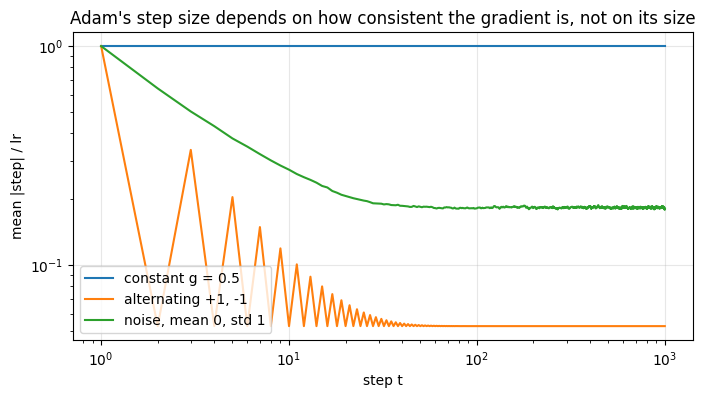

In [12]:
def adam_step_sizes(gen_grad, n_weights=10_000, steps=1000, b1=0.9, b2=0.999, eps=1e-8):
    """Mean |step| / lr at every step, for n_weights independent weights fed gradients by gen_grad(t).

    Example: adam_step_sizes(lambda t: torch.full((10,), 0.5), 10, 3) -> tensor([1., 1., 1.])
    """
    m = torch.zeros(n_weights, dtype=torch.float64); v = torch.zeros_like(m); out = []
    for t in range(1, steps + 1):
        g = gen_grad(t)
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g * g
        out.append(((m / (1 - b1 ** t)) / ((v / (1 - b2 ** t)).sqrt() + eps)).abs().mean().item())
    return np.array(out)

gnoise = torch.Generator().manual_seed(0)
cases = {"constant g = 0.5": lambda t: torch.full((10_000,), 0.5, dtype=torch.float64),
         "alternating +1, -1": lambda t: torch.full((10_000,), 1.0 if t % 2 else -1.0, dtype=torch.float64),
         "noise, mean 0, std 1": lambda t: torch.randn(10_000, generator=gnoise, dtype=torch.float64)}
pred = {"constant g = 0.5": 1.0, "alternating +1, -1": 0.1 / 1.9, "noise, mean 0, std 1": math.sqrt(0.1 / 1.9) * math.sqrt(2 / math.pi)}
curves = {k: adam_step_sizes(f) for k, f in cases.items()}
print(f"{'gradient sequence':22s} {'predicted':>10s} {'steps 1-10':>11s} {'steps 1-100':>12s} {'steps 1-1000':>13s} {'steps 500-1000':>15s}   (mean |step| / lr)")
for k, c in curves.items():
    print(f"{k:22s} {pred[k]:10.3f} {c[:10].mean():11.3f} {c[:100].mean():12.3f} {c.mean():13.3f} {c[500:].mean():15.3f}")
R["noisy_step_over_lr_steady"] = float(curves["noise, mean 0, std 1"][500:].mean())
R["noisy_step_over_lr_first100"] = float(curves["noise, mean 0, std 1"][:100].mean())

plt.figure(figsize=(8, 4))
for k, c in curves.items():
    plt.plot(np.arange(1, len(c) + 1), c, label=k)
plt.xscale("log"); plt.yscale("log"); plt.xlabel("step t"); plt.ylabel("mean |step| / lr")
plt.title("Adam's step size depends on how consistent the gradient is, not on its size"); plt.legend(); plt.grid(alpha=0.3)
savefig("adam_step_vs_consistency.png")

### 1e. L2 regularization against decoupled weight decay (AdamW)

**L2** adds $\tfrac12\lambda w^2$ to the loss, so $\lambda w$ is added to the gradient *before* Adam divides by
$\sqrt{\hat v}$. **AdamW** shrinks $w$ by $\eta\lambda w$ *outside* the division.

Setup (the lesson's): $w = 0.5$, $\lambda = 0.1$, $\eta = 10^{-3}$, so AdamW removes $\eta\lambda w = 5 \times 10^{-5}$
per step from every weight. Weight A gets large gradients, weight B gets gradients 100 times smaller. The lesson
fixes $\sqrt{\hat v}$ at the gradient size and predicts L2 shrinks B by $5\times10^{-5}/0.01 = 5\times10^{-3}$ per step,
100 times more than A.

But the decay term $\lambda w = 0.05$ also enters $\hat v$, and Adam's step can never be much larger than $\eta$.
So the honest prediction for B is "about $\eta = 10^{-3}$ per step" (the decay dominates its gradient and is applied
at full Adam strength), about 20 times A, not 100 times. If the gradients were constant rather than noisy, L2 would
add *nothing* under Adam: $g + \lambda w$ keeps the same sign, so the step stays exactly $\eta$ with or without it.

To measure the decay alone, we use mean-zero noisy gradients (std 1 for A, 0.01 for B), 20,000 copies of each weight,
300 steps, and compare against the same run with $\lambda = 0$. PyTorch's `Adam(weight_decay=...)` is the L2 version;
`AdamW` is the decoupled one.

In [13]:
def decay_per_step(noise_std, opt_cls, wd, n=20_000, steps=300, lr=1e-3, seed=0):
    """Mean shrinkage per step caused by weight decay: (w_without_decay - w_with_decay) / steps, averaged over n copies.

    Example: decay_per_step(1.0, torch.optim.AdamW, 0.1) -> about 5e-5  ( = lr * wd * w = 1e-3 * 0.1 * 0.5 )
    """
    def final_mean(decay):
        g = torch.Generator().manual_seed(seed)                     # same noise with and without decay
        w = torch.full((n,), 0.5, dtype=torch.float64, requires_grad=True)
        opt = opt_cls([w], lr=lr, betas=(0.9, 0.999), weight_decay=decay, foreach=False)
        for _ in range(steps):
            w.grad = noise_std * torch.randn(n, generator=g, dtype=torch.float64)
            opt.step()
        return w.detach().mean().item()
    return (final_mean(0.0) - final_mean(wd)) / steps

print("shrinkage per step caused by weight decay (lambda = 0.1, w = 0.5, lr = 1e-3), measured over 300 steps")
print(f"{'':32s} {'L2: Adam(weight_decay)':>24s} {'decoupled: AdamW':>18s}")
res = {}
for name, s in (("A: gradient noise std 1.0", 1.0), ("B: gradient noise std 0.01", 0.01)):
    res[name] = (decay_per_step(s, torch.optim.Adam, 0.1), decay_per_step(s, torch.optim.AdamW, 0.1))
    print(f"{name:32s} {res[name][0]:24.2e} {res[name][1]:18.2e}")
ratio_l2 = res["B: gradient noise std 0.01"][0] / res["A: gradient noise std 1.0"][0]
ratio_w = res["B: gradient noise std 0.01"][1] / res["A: gradient noise std 1.0"][1]
print(f"\nB decayed / A decayed: L2 {ratio_l2:.1f}x   AdamW {ratio_w:.2f}x   (lesson's idealised L2 figure: 100x)")
R["l2_B_over_A"] = ratio_l2; R["adamw_B_over_A"] = ratio_w

shrinkage per step caused by weight decay (lambda = 0.1, w = 0.5, lr = 1e-3), measured over 300 steps
                                   L2: Adam(weight_decay)   decoupled: AdamW
A: gradient noise std 1.0                        4.90e-05           4.93e-05
B: gradient noise std 0.01                       8.37e-04           4.93e-05

B decayed / A decayed: L2 17.1x   AdamW 1.00x   (lesson's idealised L2 figure: 100x)


### 1f. Optimizer memory, measured

For every weight, training stores the weight, its gradient and Adam's $m$ and $v$. In this notebook the weights are
kept in fp32 and autocast makes bf16 copies on the fly for each matmul, so the gradients are fp32 too:

$$4 \text{ (weight)} + 4 \text{ (gradient)} + 4\ (m) + 4\ (v) = 16 \text{ bytes per weight}$$

The lesson splits the same 16 bytes differently (2 + 2 + 4 + 4 + 4 with bf16 weights and gradients plus an fp32
master copy). In both, **half the bytes are optimizer state**. Prediction for our 49.3M model: $16 \times 49.26\text{M} = 788$ MB,
of which 394 MB is $m$ and $v$. SGD with momentum keeps only $m$ (12 bytes per weight).

In [14]:
torch.manual_seed(0)
mdl = GPT(Config()).to(device)
N = sum(p.numel() for p in mdl.parameters())
def state_bytes(opt):
    return sum(v.numel() * v.element_size() for st in opt.state.values() for v in st.values() if torch.is_tensor(v) and v.dim() > 0)
x, y = get_batch(torch.Generator().manual_seed(0))
rows = []
for name, opt in (("SGD (no momentum)", torch.optim.SGD(mdl.parameters(), lr=1e-3)),
                  ("SGD + momentum", torch.optim.SGD(mdl.parameters(), lr=1e-3, momentum=0.9)),
                  ("AdamW", torch.optim.AdamW(mdl.parameters(), lr=1e-3))):
    with torch.autocast("cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
        loss = F.cross_entropy(mdl(x).float().reshape(-1, 50304), y.reshape(-1))
    opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    w_b = sum(p.numel() * p.element_size() for p in mdl.parameters())
    g_b = sum(p.grad.numel() * p.grad.element_size() for p in mdl.parameters())
    s_b = state_bytes(opt)
    rows.append((name, w_b / N, g_b / N, s_b / N))
    del opt
print(f"measured bytes per weight on our {N / 1e6:.2f}M-weight model")
print(f"{'optimizer':20s} {'weight':>7s} {'grad':>6s} {'state':>6s} {'total':>6s}   {'our model':>10s}   {'a 9B model':>11s}")
for name, wb, gb, sb in rows:
    tot = wb + gb + sb
    print(f"{name:20s} {wb:7.1f} {gb:6.1f} {sb:6.1f} {tot:6.1f}   {tot * N / 2**20:7.0f} MiB   {tot * 9e9 / 2**30:7.1f} GiB")
R["adamw_bytes_per_weight"] = sum(rows[-1][1:])
print("\nlesson's 9B table: gradient descent 67.1 GiB, momentum 100.6 GiB, AdamW 134.1 GiB (8, 12, 16 bytes per weight)")
del mdl

measured bytes per weight on our 49.26M-weight model
optimizer             weight   grad  state  total    our model    a 9B model
SGD (no momentum)        4.0    4.0    0.0    8.0       376 MiB      67.1 GiB
SGD + momentum           4.0    4.0    4.0   12.0       564 MiB     100.6 GiB
AdamW                    4.0    4.0    8.0   16.0       752 MiB     134.1 GiB

lesson's 9B table: gradient descent 67.1 GiB, momentum 100.6 GiB, AdamW 134.1 GiB (8, 12, 16 bytes per weight)


### Observations (Section 1)

- **The lesson's table is reproduced exactly.** $w$ = 0.999000, 0.998012, 0.997018, 0.996028, 0.995031, the same to
  six decimals. The gradients vary by 50% (0.40 to 0.60) but every step is within 1.19% of $\eta$.
- **PyTorch agrees.** In float64, `Adam` and `AdamW` give the same $w$ as the hand computation to the last bit
  (difference 0), and $m$, $v$ agree to $10^{-17}$. In float32 the largest difference is $1.3\times10^{-8}$ (Adam) and
  $3.1\times10^{-8}$ (AdamW), less than one float32 spacing near 1 ($1.19\times10^{-7}$), so it is rounding.
- **On a real 442,368-weight matrix with real gradients**, `HandAdamW` and `torch.optim.AdamW` differ by at most
  $1.49\times10^{-8} = 2^{-26}$, exactly one float32 spacing for weights between 0.125 and 0.25. A typical step is
  $10^{-3}$ to $3.5\times10^{-4}$, so that is 5 orders of magnitude smaller. For element [0, 0], plain Python and
  PyTorch end 5 steps at 0.04327320 and 0.04327319.
- Two things the real-gradient table shows that the lesson's example does not. (1) The first step is
  $-0.99975\,\eta$, not exactly $-\eta$: this weight's gradient is about $4\times10^{-5}$, so $\epsilon = 10^{-8}$ is no
  longer negligible next to $\sqrt{\hat v}$. (2) The mean step over the whole matrix falls from $9.99\times10^{-4}$ at step 1 to
  $3.48\times10^{-4}$ at step 5. Gradients stop agreeing with each other within a few steps.
- **Step size against consistency (1d).** All three predictions held: constant 1.000, alternating 0.053, noise
  0.183 (steady state). **The lesson's $0.281\eta$ for noisy gradients was not reproduced.** The average is 0.448 over
  the first 10 steps, 0.216 over the first 100 and 0.183 at steady state, so 0.281 would need an averaging window of
  a few dozen steps, or a setting the lesson does not state.
- **L2 against AdamW (1e).** AdamW shrinks both weights by $4.93\times10^{-5}$ per step ($\eta\lambda w$ = $5\times10^{-5}$,
  as predicted, ratio 1.00). L2 shrinks the small-gradient weight B by $8.37\times10^{-4}$ and A by $4.90\times10^{-5}$:
  **17 times more, not the lesson's 100 times.** The lesson holds $\sqrt{\hat v}$ fixed at the gradient size, but for
  B the decay term $\lambda w = 0.05$ is five times its gradient noise, so it dominates both $\hat m$ and $\hat v$ and
  Adam applies it at nearly a full step ($0.84\eta$). Adam cannot move a weight much more than $\eta$, which caps the
  gap.
- **Memory (1f).** Measured 4 + 4 + 8 = **16.0 bytes per weight** for AdamW (752 MiB for 49.26M weights), 12 for SGD
  with momentum, 8 for plain SGD. Scaled to 9B weights: 67.1 / 100.6 / 134.1 GiB, the lesson's table exactly. Half
  the AdamW bill is $m$ and $v$.

## 2. Bias correction switched off

### 2a. What switching it off does, exactly

Without bias correction the update uses $m$ and $v$ directly. Writing $m = \hat m (1-\beta_1^t)$ and
$v = \hat v (1-\beta_2^t)$:

$$\frac{m}{\sqrt{v}} = \frac{\hat m}{\sqrt{\hat v}} \cdot \underbrace{\frac{1-\beta_1^t}{\sqrt{1-\beta_2^t}}}_{c(t)}$$

So the uncorrected step is the corrected step multiplied by a number $c(t)$ that depends **only on the step count**,
not on the gradients or the model. That makes "when does the difference stop mattering" a question that can be
answered on paper: when $c(t)$ is close to 1. (This holds whenever $\epsilon$ is negligible next to $\sqrt v$.)

Hand values with $\beta_1 = 0.9$:

| $t$ | $\beta_2 = 0.999$: $c(t)$ | $\beta_2 = 0.95$: $c(t)$ |
|---:|---:|---:|
| 1 | $0.1/\sqrt{0.001} = 3.16$ | $0.1/\sqrt{0.05} = 0.447$ |
| 12 | $0.718/\sqrt{0.01193} = 6.57$ (the peak) | $0.718/\sqrt{0.4596} = 1.06$ |
| 20 | $0.878/\sqrt{0.0198} = 6.24$ | $0.878/\sqrt{0.6415} = 1.10$ |

Two surprises before running anything:

1. With the default $\beta_2 = 0.999$ the uncorrected step does not just start too large, it **grows** to 6.6 times
   too large around step 12. The numerator ($m$'s bias) recovers within about 40 steps, the denominator ($v$'s bias)
   needs thousands. Within 1% of the corrected step only after **about 3,900 steps**.
2. With $\beta_2 = 0.95$ (the usual choice for language models) the uncorrected first step is *smaller* than the
   corrected one (0.45 times). Missing bias correction then acts like a short built-in warmup, and $c(t)$ is
   within 1% of 1 after **about 76 steps**.

The first plot and table compute $c(t)$ exactly; the second plot shows the first 20 steps of real weights, and 2c
asks whether any of it is visible in the loss of a real model.

**How to read "within 10%" and "within 1%" in the table below.** "Within 1% from step N" means: from step N onward
the uncorrected step is always between 0.99 and 1.01 times the corrected step, that is $0.99 < c(t) < 1.01$ for every
later step, and before step N it was outside that range at least once. "Within 10%" uses 0.90 to 1.10 instead. These
are the two answers to "after how many steps does the difference stop mattering", for a loose and a strict meaning
of "stops mattering".

c(t) = uncorrected step / corrected step, beta1 = 0.9
 beta2       1       2       5      10      12      20      50     100     500    1000    2000    4000
 0.999   3.162   4.250   5.797   6.528   6.569   6.241   4.504   3.241   1.594   1.258   1.075   1.009
  0.99   1.000   1.347   1.850   2.106   2.129   2.059   1.583   1.256   1.003   1.000   1.000   1.000
  0.95   0.447   0.608   0.861   1.028   1.058   1.097   1.035   1.003   1.000   1.000   1.000   1.000

 beta2  peak c(t)  at step  within 10% from  within 1% from
 0.999      6.569       12            1,751           3,925
  0.99      2.131       13              175             391
  0.95      1.097       20                6              76

for comparison, m's correction alone (1 - 0.9^t) is within 1% of 1 from step 44


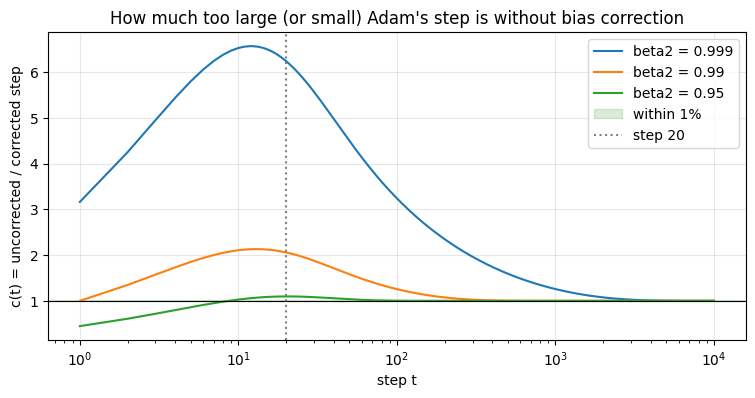

In [15]:
def bias_factor(t, b1=0.9, b2=0.999):
    """c(t) = (1 - b1^t) / sqrt(1 - b2^t): uncorrected Adam step divided by the corrected one.

    Example: bias_factor(1) -> 3.162;  bias_factor(1, b2=0.95) -> 0.447
    """
    t = np.asarray(t, dtype=float)
    return (1 - b1 ** t) / np.sqrt(1 - b2 ** t)

def first_step_within(tol, b1=0.9, b2=0.999, t_max=200_000):
    """First step after which |c(t) - 1| < tol for every later step."""
    t = np.arange(1, t_max + 1)
    bad = np.where(np.abs(bias_factor(t, b1, b2) - 1) >= tol)[0]
    return int(t[bad[-1] + 1]) if len(bad) else 1

ts = [1, 2, 5, 10, 12, 20, 50, 100, 500, 1000, 2000, 4000]
print("c(t) = uncorrected step / corrected step, beta1 = 0.9")
print(f"{'beta2':>6}" + "".join(f"{t:>8d}" for t in ts))
for b2 in (0.999, 0.99, 0.95):
    print(f"{b2:>6}" + "".join(f"{bias_factor(t, b2=b2):8.3f}" for t in ts))
print()
print(f"{'beta2':>6} {'peak c(t)':>10} {'at step':>8} {'within 10% from':>16} {'within 1% from':>15}")
for b2 in (0.999, 0.99, 0.95):
    tt = np.arange(1, 20001); c = bias_factor(tt, b2=b2)
    print(f"{b2:>6} {c.max():10.3f} {tt[c.argmax()]:8d} {first_step_within(0.10, b2=b2):16,d} {first_step_within(0.01, b2=b2):15,d}")
    R[f"bias_within1pct_b2_{b2}"] = first_step_within(0.01, b2=b2)
print(f"\nfor comparison, m's correction alone (1 - 0.9^t) is within 1% of 1 from step {int(np.ceil(np.log(0.01) / np.log(0.9)))}")

tt = np.arange(1, 10001)
plt.figure(figsize=(9, 4))
for b2 in (0.999, 0.99, 0.95):
    plt.plot(tt, bias_factor(tt, b2=b2), label=f"beta2 = {b2}")
plt.axhline(1, color="k", lw=0.8); plt.axhspan(0.99, 1.01, color="g", alpha=0.15, label="within 1%")
plt.axvline(20, color="gray", ls=":", label="step 20")
plt.xscale("log"); plt.xlabel("step t"); plt.ylabel("c(t) = uncorrected / corrected step")
plt.title("How much too large (or small) Adam's step is without bias correction"); plt.legend(); plt.grid(alpha=0.3)
savefig("bias_correction_factor.png")

### 2b. The first 20 steps of real weights, both ways

We record the real gradients of 1,024 weights of `blocks.0.attn.qkv` during the first 20 training steps of the real
model. From them we pick the weight whose gradient was **most consistent** (largest $|\text{mean}|/\text{std}$) and
the one that was **least consistent**, and push each weight's 20 gradients through Adam with and without bias
correction, for both $\beta_2$ values. Feeding the same gradients to both versions isolates the optimizer: the weight
itself does not feed back into its gradients here (2c does the closed-loop version).

**Prediction:** the ratio of the two step sizes follows $c(t)$ exactly for both weights (3.16 at step 1, about 6.2 at
step 20 for $\beta_2 = 0.999$), whatever their gradients do. So within 20 steps the difference never stops
mattering for $\beta_2 = 0.999$. Displacements after 20 steps should differ by roughly a factor of 5.
One way this prediction can fail: real gradients here are small (around $10^{-5}$ or less), and without correction
$\sqrt{v}$ is only $\sqrt{0.001} \approx 3\%$ of $|g|$ at step 1, which can come close to $\epsilon = 10^{-8}$.
Where it does, the uncorrected step is smaller than $c(t)$ predicts.

**How to read the plot.** Each row is one weight; the three panels are:

| Panel | What it shows |
|---|---|
| left, "its 20 real gradients" | the gradient this weight received at each of the 20 steps |
| middle, `|step| / lr` | how far the weight moved at that step, divided by the learning rate. 1 means it moved exactly $\eta = 0.001$; 4 means four times that. The direction is ignored |
| right, `weight position w_t - w_0` | where the weight is after $t$ steps, measured from its starting value: the running total of all its steps, with direction |

Blue lines use bias correction, red lines do not. Solid lines use $\beta_2 = 0.999$, dashed lines $\beta_2 = 0.95$.

most consistent gradient: qkv weight #977, |mean|/std = 0.66, gradients: +7.5e-06, +1.0e-05, +5.1e-06, -4.0e-07, +2.1e-07, +1.1e-06, ...
   beta2=0.999: uncorrected/corrected step at t=1, 12, 20: 3.038, 6.439, 6.126  (c(t) = 3.162, 6.569, 6.241);  displacement after 20 steps: with -0.01063, without -0.05882
   beta2=0.95: uncorrected/corrected step at t=1, 12, 20: 0.445, 1.057, 1.096  (c(t) = 0.447, 1.058, 1.097);  displacement after 20 steps: with -0.01142, without -0.01021
least consistent gradient: qkv weight #271, |mean|/std = 0.00, gradients: -6.2e-05, +5.6e-05, -1.9e-06, +1.5e-07, +9.5e-07, -1.3e-06, ...
   beta2=0.999: uncorrected/corrected step at t=1, 12, 20: 3.147, 6.547, 6.221  (c(t) = 3.162, 6.569, 6.241);  displacement after 20 steps: with +0.00084, without +0.00207
   beta2=0.95: uncorrected/corrected step at t=1, 12, 20: 0.447, 1.058, 1.097  (c(t) = 0.447, 1.058, 1.097);  displacement after 20 steps: with +0.00079, without +0.00021


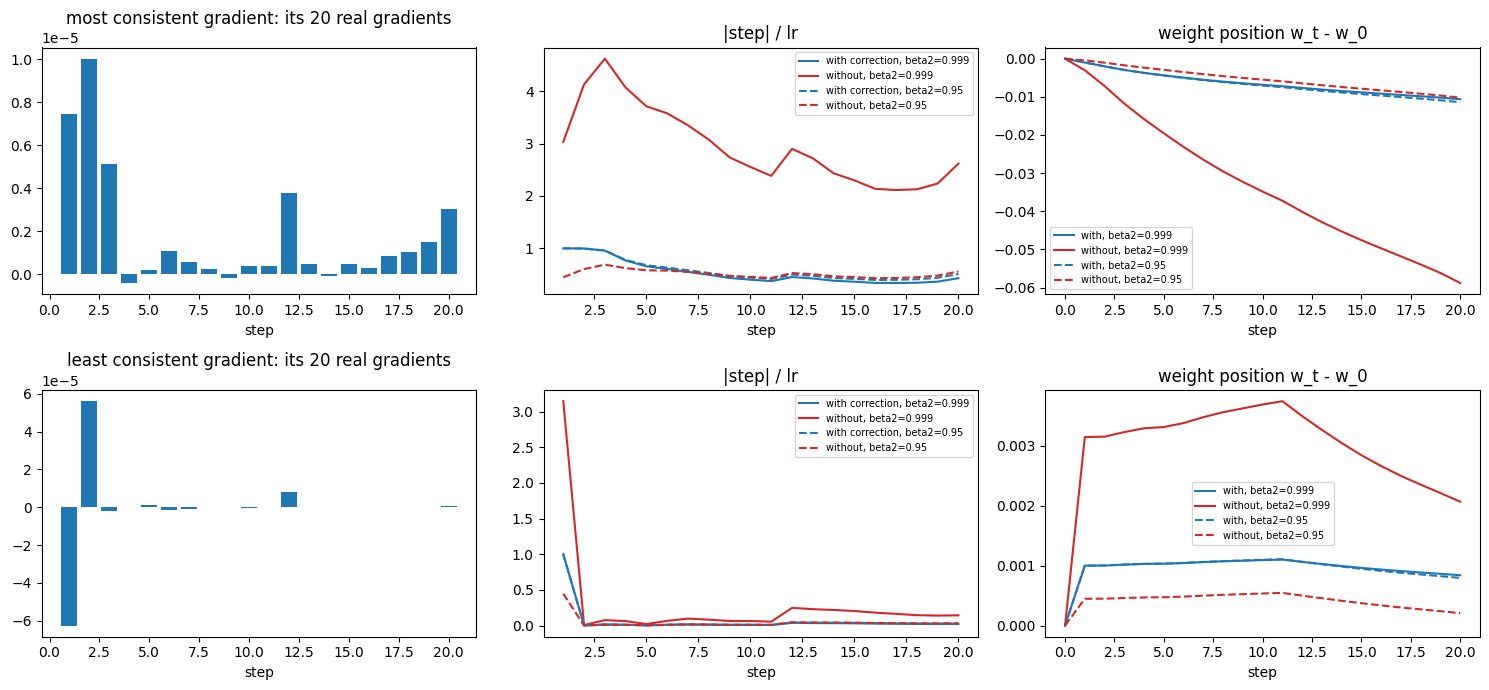

In [16]:
probe = []
def record_qkv_grad(model, t):
    probe.append(model.blocks[0].attn.qkv.weight.grad[:32, :32].flatten().double().cpu().clone())

_ = train_run(Config(), 1e-3, constant(0), steps=20, betas=(0.9, 0.999), eval_every=20, grad_probe=record_qkv_grad, label="gradient recording")
G = torch.stack(probe)                                                  # (20 steps, 1024 weights)
consistency = G.mean(0).abs() / G.std(0)
picks = {"most consistent gradient": int(consistency.argmax()), "least consistent gradient": int(consistency.argmin())}

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for row, (title, j) in enumerate(picks.items()):
    gseq = G[:, j].tolist()
    print(f"{title}: qkv weight #{j}, |mean|/std = {consistency[j]:.2f}, gradients: " + ", ".join(f"{g:+.1e}" for g in gseq[:6]) + ", ...")
    axes[row, 0].bar(range(1, 21), gseq); axes[row, 0].set_title(f"{title}: its 20 real gradients"); axes[row, 0].set_xlabel("step")
    for b2, ls in ((0.999, "-"), (0.95, "--")):
        on = adam_by_hand(0.0, gseq, b2=b2)
        off = adam_by_hand(0.0, gseq, b2=b2, bias_correction=False)
        s_on = np.array([abs(r["step"]) for r in on]) / 1e-3; s_off = np.array([abs(r["step"]) for r in off]) / 1e-3
        axes[row, 1].plot(range(1, 21), s_on, ls, color="C0", label=f"with correction, beta2={b2}")
        axes[row, 1].plot(range(1, 21), s_off, ls, color="C3", label=f"without, beta2={b2}")
        axes[row, 2].plot(range(0, 21), [0] + [r["w"] for r in on], ls, color="C0", label=f"with, beta2={b2}")
        axes[row, 2].plot(range(0, 21), [0] + [r["w"] for r in off], ls, color="C3", label=f"without, beta2={b2}")
        ratio = s_off / s_on
        print(f"   beta2={b2}: uncorrected/corrected step at t=1, 12, 20: {ratio[0]:.3f}, {ratio[11]:.3f}, {ratio[19]:.3f}"
              f"  (c(t) = {bias_factor(1, b2=b2):.3f}, {bias_factor(12, b2=b2):.3f}, {bias_factor(20, b2=b2):.3f});"
              f"  displacement after 20 steps: with {on[-1]['w']:+.5f}, without {off[-1]['w']:+.5f}")
    axes[row, 1].set_title("|step| / lr"); axes[row, 1].set_xlabel("step"); axes[row, 1].legend(fontsize=7)
    axes[row, 2].set_title("weight position w_t - w_0"); axes[row, 2].set_xlabel("step"); axes[row, 2].legend(fontsize=7)
plt.tight_layout()
savefig("bias_correction_20_steps.png")

### 2c. Does it show up in the loss of a real model?

Closed loop now: train the real 49M model for 300 steps with our `HandAdamW`, bias correction on and off, at a
constant $\eta = 10^{-3}$ **without warmup** (the case where missing correction should hurt most), for
$\beta_2 = 0.999$ and $\beta_2 = 0.95$. Two more runs with a 100-step warmup show whether warmup hides the missing
correction, and one run with a different seed measures how much two healthy runs differ anyway (the noise floor).

**Definition used for "stops mattering" on the real model:** the first step after which the smoothed training-loss
gap between the corrected and uncorrected runs stays below the seed-to-seed gap (twice its typical size) for the
rest of the run.

**Prediction:** with $\beta_2 = 0.999$ and no warmup, the uncorrected run takes steps up to 6.6 times too large in
the first tens of steps. This is where a loss spike or slower start should appear. With $\beta_2 = 0.95$ the two runs
should be almost indistinguishable. Whether the $\beta_2 = 0.999$ gap closes by step 300 depends on whether the early
damage is permanent, which I cannot predict.

In [17]:
def smooth(x, w=20):
    """Trailing moving average with window w (shorter at the start). Same length as x.

    Example: smooth([1, 2, 3, 4], 2) -> [1.0, 1.5, 2.5, 3.5]
    """
    x = np.asarray(x, dtype=float); c = np.cumsum(np.insert(x, 0, 0.0))
    idx = np.arange(1, len(x) + 1); lo = np.maximum(0, idx - w)
    return (c[idx] - c[lo]) / (idx - lo)

def stops_mattering(gap, band):
    """First 1-based step after which |gap| < band at every later step, or None if it never settles.

    Example: stops_mattering([0.5, 0.2, 0.01, 0.02, 0.01], 0.05) -> 3
    """
    bad = np.where(np.abs(np.asarray(gap)) >= band)[0]
    if len(bad) == 0:
        return 1
    return None if bad[-1] == len(gap) - 1 else int(bad[-1] + 2)

runs2 = {}
spec = [("beta2=0.999, corrected", dict(betas=(0.9, 0.999), bias_correction=True), 0, 0),
        ("beta2=0.999, uncorrected", dict(betas=(0.9, 0.999), bias_correction=False), 0, 0),
        ("beta2=0.95, corrected", dict(betas=(0.9, 0.95), bias_correction=True), 0, 0),
        ("beta2=0.95, uncorrected", dict(betas=(0.9, 0.95), bias_correction=False), 0, 0),
        ("beta2=0.999, corrected, warmup 100", dict(betas=(0.9, 0.999), bias_correction=True), 100, 0),
        ("beta2=0.999, uncorrected, warmup 100", dict(betas=(0.9, 0.999), bias_correction=False), 100, 0),
        ("beta2=0.999, corrected, seed 1", dict(betas=(0.9, 0.999), bias_correction=True), 0, 1)]
t0 = time.time()
for name, kw, W, seed in spec:
    runs2[name] = train_run(Config(), 1e-3, constant(W), optimizer="hand", seed=seed, label=name, **kw)
    h = runs2[name]
    print(f"{name:38s} max train loss in steps 2-60: {max(h['train_loss'][1:60]):6.3f}   held-out loss at 100 / 200 / 300: "
          + " / ".join(f"{h['eval'].get(s, float('nan')):.4f}" for s in (100, 200, 300)) + ("   DIVERGED" if h["diverged"] else ""))
print(f"[{time.time() - t0:.0f} s for {len(spec)} runs]")

beta2=0.999, corrected                 max train loss in steps 2-60: 10.661   held-out loss at 100 / 200 / 300: 4.6931 / 3.6840 / 3.2310
beta2=0.999, uncorrected               max train loss in steps 2-60: 10.557   held-out loss at 100 / 200 / 300: 4.9497 / 4.5197 / 4.2111
beta2=0.95, corrected                  max train loss in steps 2-60: 10.661   held-out loss at 100 / 200 / 300: 4.7378 / 3.7065 / 3.2426
beta2=0.95, uncorrected                max train loss in steps 2-60: 10.709   held-out loss at 100 / 200 / 300: 4.6718 / 3.6871 / 3.2664
beta2=0.999, corrected, warmup 100     max train loss in steps 2-60: 10.821   held-out loss at 100 / 200 / 300: 4.8128 / 3.4762 / 3.0512
beta2=0.999, uncorrected, warmup 100   max train loss in steps 2-60: 10.811   held-out loss at 100 / 200 / 300: 4.9708 / 4.1327 / 3.7221
beta2=0.999, corrected, seed 1         max train loss in steps 2-60: 10.697   held-out loss at 100 / 200 / 300: 4.5708 / 3.6437 / 3.2493
[109 s for 7 runs]


seed-to-seed noise: mean |smoothed gap| over steps 100-300 = 0.0449 nats  ->  band = 0.0897 nats
seed-to-seed held-out gap at step 300 = 0.0183 nats

comparison                                            stops mattering at step  held-out gap at 300
beta2=0.999, uncorrected minus corrected                       not within 300              +0.9801
beta2=0.95, uncorrected minus corrected                                    63              +0.0238
beta2=0.999, uncorrected, warmup 100 minus corrected           not within 300              +0.6709


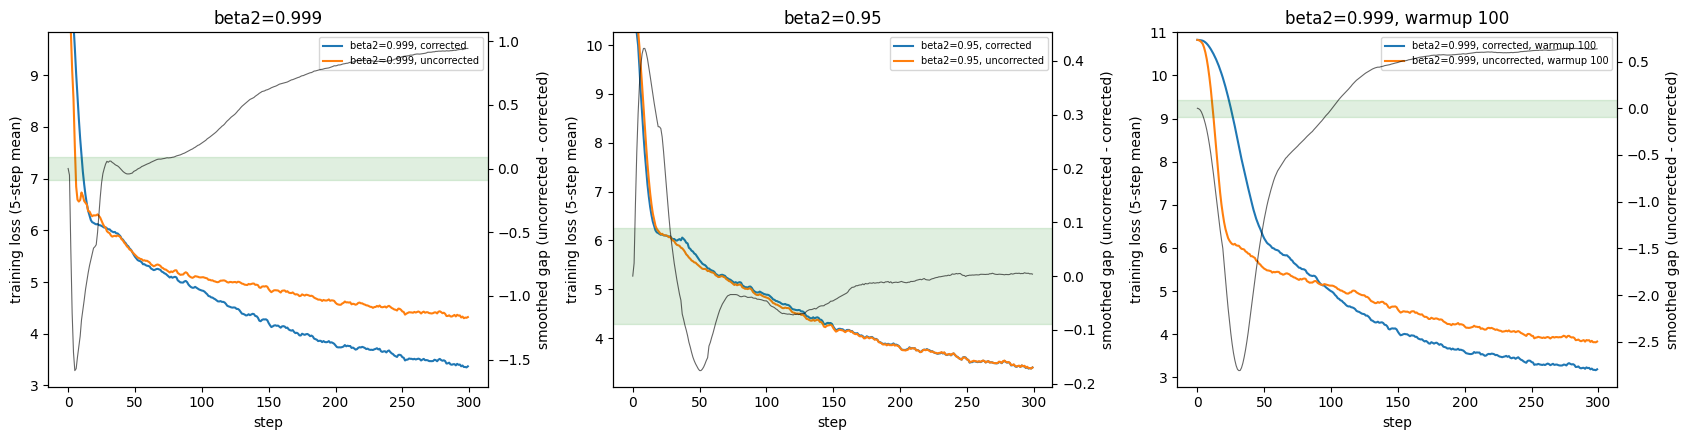

In [18]:
base, seed1 = runs2["beta2=0.999, corrected"], runs2["beta2=0.999, corrected, seed 1"]
noise_gap = smooth(np.array(base["train_loss"]) - np.array(seed1["train_loss"]))
band = 2 * np.abs(noise_gap[100:]).mean()
print(f"seed-to-seed noise: mean |smoothed gap| over steps 100-300 = {band / 2:.4f} nats  ->  band = {band:.4f} nats")
print(f"seed-to-seed held-out gap at step 300 = {abs(base['eval'][300] - seed1['eval'][300]):.4f} nats\n")
print(f"{'comparison':52s} {'stops mattering at step':>24s} {'held-out gap at 300':>20s}")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax_i, (a, b) in enumerate([("beta2=0.999, corrected", "beta2=0.999, uncorrected"),
                               ("beta2=0.95, corrected", "beta2=0.95, uncorrected"),
                               ("beta2=0.999, corrected, warmup 100", "beta2=0.999, uncorrected, warmup 100")]):
    ha, hb = runs2[a], runs2[b]
    n = min(len(ha["train_loss"]), len(hb["train_loss"]))
    gap = smooth(np.array(hb["train_loss"][:n]) - np.array(ha["train_loss"][:n]))
    s = stops_mattering(gap, band)
    eg = hb["eval"].get(300, float("nan")) - ha["eval"].get(300, float("nan"))
    print(f"{b + ' minus corrected':52s} {str(s) if s else 'not within 300':>24s} {eg:+20.4f}")
    R[f"task2_real_stops_mattering[{b}]"] = s; R[f"task2_real_gap300[{b}]"] = eg
    ax = axes[ax_i]
    ax.plot(smooth(ha["train_loss"], 5), label=a); ax.plot(smooth(hb["train_loss"], 5), label=b)
    ax.set_ylim(top=min(11, max(max(smooth(ha["train_loss"], 5)[5:]), max(smooth(hb["train_loss"], 5)[5:])) + 0.3))
    ax2 = ax.twinx(); ax2.plot(gap, color="k", lw=0.8, alpha=0.6); ax2.axhspan(-band, band, color="g", alpha=0.12)
    ax2.set_ylabel("smoothed gap (uncorrected - corrected)")
    ax.set_xlabel("step"); ax.set_ylabel("training loss (5-step mean)"); ax.legend(fontsize=7, loc="upper right"); ax.set_title(b.replace(", uncorrected", ""))
plt.tight_layout()
savefig("bias_correction_real_model.png")

### Observations (Section 2)

**Answer to the task.** Switching off bias correction multiplies every Adam step by $c(t) = (1-\beta_1^t)/\sqrt{1-\beta_2^t}$.
With the lesson's $\beta_2 = 0.999$ the difference **does not stop mattering within the first 20 steps at all**. The
uncorrected step is 3.16 times too large at step 1, 6.57 times at step 12 (the peak) and 6.24 times at step 20. It
gets within 10% of the corrected step after **1,751 steps** and within 1% after **3,925 steps**. With $\beta_2 = 0.95$
it is within 10% after 6 steps and within 1% after **76 steps**. On the real model with $\beta_2 = 0.95$ the
loss difference falls inside the seed-to-seed noise from **step 63** onwards.

- **20 real steps (2b).** The ratio of the two step sizes followed $c(t)$ for both chosen weights: 3.15 / 6.55 /
  6.22 at steps 1 / 12 / 20 for one weight, and 3.04 / 6.44 / 6.13 for the other (predicted 3.16 / 6.57 / 6.24). The
  second weight lands slightly below because its gradients are $10^{-7}$ to $10^{-5}$, where $\epsilon$ starts to
  matter, as warned. After 20 steps the consistent weight had moved 0.0106 with correction and **0.0588 without (5.5
  times further)**. With $\beta_2 = 0.95$ the two versions moved 0.0114 and 0.0102: practically the same.
- **Real model, $\beta_2 = 0.999$, no warmup (2c).** No loss spike, and the result is not what I expected.
  For the first ~25 steps the uncorrected run is *ahead*: its smoothed training loss is up to 1.5 nats lower near
  step 5, because the loss is falling from 10.8 and larger steps help there. It falls behind after step ~30 and
  never recovers. Held-out loss at 300 is **4.211 against 3.231 (+0.98 nats)**, while two seeds of the
  corrected run differ by only 0.018. The reason is that $c(t)$ is still 3.24 at step 100 and 1.96 at step 300, so
  the uncorrected run trains at 2 to 6.6 times the intended rate for the whole run. The sweeps in Sections 4 and 5
  show this model is worse at such rates.
- **Warmup does not rescue it.** With a 100-step warmup the uncorrected run still ends +0.67 nats behind. Warmup
  scales $\eta$ for the first 100 steps, but $c(t)$ peaks at step 12 and stays above 2 until about step 290, so
  most of the damage is after warmup ends.
- **$\beta_2 = 0.95$ is harmless:** +0.024 nats at step 300, about the seed-to-seed gap (0.018). The uncorrected
  first step is smaller (0.45 times) and the factor never exceeds 1.10.
- **Lesson for practice:** bias correction matters mainly because of $\beta_2$. With $\beta_2 = 0.999$ the second
  moment's bias lasts thousands of steps. With the $\beta_2 = 0.95$ that LLM recipes use, it is gone within about 76
  steps, so the correction then matters much less.

## 3. The update-to-weight ratio, layer by layer

### 3a. What it is, and how warmup controls it

For one weight tensor $W$, the **update-to-weight ratio** of a step is

$$r_t = \frac{\lVert W_t - W_{t-1} \rVert}{\lVert W_{t-1} \rVert}$$

the fraction of the tensor's own size that one step changes. The lesson's rule of thumb is that it should stay near
$10^{-3}$: much larger and every step rewrites the layer, much smaller and the layer is not learning.

**Why it is tied to the learning rate.** Adam moves every element by about $\eta \times (\text{a factor between
0 and 1 that measures gradient consistency})$, as Section 1d showed. A tensor with $n$ elements, each moved by about
$\eta k$, changes by $\lVert\Delta W\rVert \approx \eta k \sqrt n$. If its elements have standard deviation $\sigma$,
then $\lVert W \rVert = \sigma \sqrt n$. The $\sqrt n$ cancels:

$$r_t \approx \frac{\eta_t \, k_t}{\sigma}$$

So $r_t$ is the learning rate in units of the tensor's own scale, times the gradient-consistency factor $k_t$.
During warmup $\eta_t$ grows linearly, so $r_t$ is **forced** upward by the schedule. After warmup $\eta_t$ is flat,
and $r_t$ moves only because $k_t$ (gradients becoming less consistent) and $\sigma$ (weights growing) change. "The
step at which warmup stops changing the ratio" is the hand-off between these two regimes.

**Hand prediction for step 1, no warmup, $\eta = 10^{-3}$.** At step 1 every gradient is perfectly "consistent"
(there is only one), so $k = 1$ exactly and every element moves by exactly $\eta$ (Section 1a). So $r_1 = \eta/\sigma$:

| tensor | init std $\sigma$ | predicted $r_1 = \eta / \sigma$ |
|---|---|---:|
| attn.qkv, mlp.gate, mlp.up (fan-in 384) | $1/\sqrt{384} = 0.0510$ | **0.0196** |
| attn.proj (fan-in 384, $/\sqrt{12}$) | $0.0147$ | 0.0679 |
| mlp.down (fan-in 1024, $/\sqrt{12}$) | $0.0090$ | 0.1109 |
| norm gains (all 1.0) | 1 | 0.0010 |
| head ($1/D$) | 0.0026 | 0.384 |
| embedding (0.02), only rows of tokens present in the batch move | 0.02 | $0.05\sqrt{\text{rows used}/50304}$ |

(Measured values can come out slightly *below* these predictions for tensors with many gradients comparable to
$\epsilon = 10^{-8}$, because then $|g|/(|g| + \epsilon) < 1$.)

The first row is the lesson's "0.0192, nineteen times too large" (it used width 4,096 and $\eta = 3\times10^{-4}$;
our width 384 and $\eta = 10^{-3}$ give almost the same number by coincidence). With a 100-step linear warmup,
$\eta_1 = \eta/100$, so the same tensors should start at $1.96 \times 10^{-4}$.

In [19]:
h1 = train_run(Config(), 1e-3, constant(0), steps=1, eval_every=1000, log_ratio=True, label="one step, no warmup")
x1, _ = get_batch(torch.Generator().manual_seed(1000))            # the batch that run used at step 1 (seed 0 -> generator 1000)
rows_used = torch.unique(x1).numel()
torch.manual_seed(0); init = dict(GPT(Config()).named_parameters())
print(f"distinct tokens in the step-1 batch: {rows_used:,} of 50,304 embedding rows receive a gradient\n")
print(f"{'tensor':28s} {'init std':>9s} {'predicted r_1':>14s} {'measured r_1':>13s}")
for name in ["embed.weight", "blocks.0.attn.qkv.weight", "blocks.0.attn.proj.weight", "blocks.0.mlp.gate.weight",
             "blocks.0.mlp.up.weight", "blocks.0.mlp.down.weight", "blocks.5.mlp.down.weight", "blocks.0.norm1.weight", "head.weight"]:
    w = init[name].detach()
    sigma = w.pow(2).mean().sqrt().item()                          # RMS of the tensor (= std for zero-mean init, 1.0 for gains)
    pred = 1e-3 / sigma * (math.sqrt(rows_used / 50304) if name == "embed.weight" else 1.0)
    meas = h1["ratio"][0][h1["ratio_names"].index(name)]
    print(f"{name:28s} {sigma:9.5f} {pred:14.5f} {meas:13.5f}")
del init

distinct tokens in the step-1 batch: 1,244 of 50,304 embedding rows receive a gradient

tensor                        init std  predicted r_1  measured r_1
embed.weight                   0.02000        0.00786       0.00785
blocks.0.attn.qkv.weight       0.05103        0.01960       0.01957
blocks.0.attn.proj.weight      0.01474        0.06783       0.06781
blocks.0.mlp.gate.weight       0.05105        0.01959       0.01955
blocks.0.mlp.up.weight         0.05100        0.01961       0.01957
blocks.0.mlp.down.weight       0.00903        0.11076       0.11071
blocks.5.mlp.down.weight       0.00903        0.11076       0.11058
blocks.0.norm1.weight          1.00000        0.00100       0.00100
head.weight                    0.00260        0.38406       0.38071


### 3b. Three runs: warmup 0, 50 and 100 steps

Same model, seed and data, peak $\eta = 10^{-3}$, $\beta_2 = 0.95$. After warmup the rate is held **constant** (no
decay), so that any change in $r_t$ after warmup cannot be blamed on the schedule. The ratio of every one of the 51
weight tensors is logged at every step.

**How we identify "the step at which warmup stops changing it"**, two ways:

1. **Hand-off:** the step at which the smoothed ratio stops rising and peaks. Prediction: at, or a few steps before,
   the end of warmup ($W = 50$ or $100$), because $\eta_t$ stops growing there while $k_t$ keeps falling.
2. **Counterfactual:** the first step after which the warmup run's ratio stays within 10% of the no-warmup run's
   ratio for the rest of the run. This answers "from when on would the ratio be the same without warmup".
   Prediction: some steps *after* $W$, because the two models have taken different paths. It may never happen if
   the paths stay different.

The plots also show $r_t / \eta_t$, which by the formula above is $k_t / \sigma$: the part of the ratio that warmup
does *not* control. It should fall fastest in the first tens of steps, the lesson's point that early gradients are
the most correlated.

warmup   0 steps: held-out loss at 100 / 200 / 300 = 4.7623 / 3.7204 / 3.2565   (15 s)
warmup  50 steps: held-out loss at 100 / 200 / 300 = 4.8466 / 3.6821 / 3.2061   (15 s)
warmup 100 steps: held-out loss at 100 / 200 / 300 = 4.7739 / 3.4634 / 3.0371   (15 s)


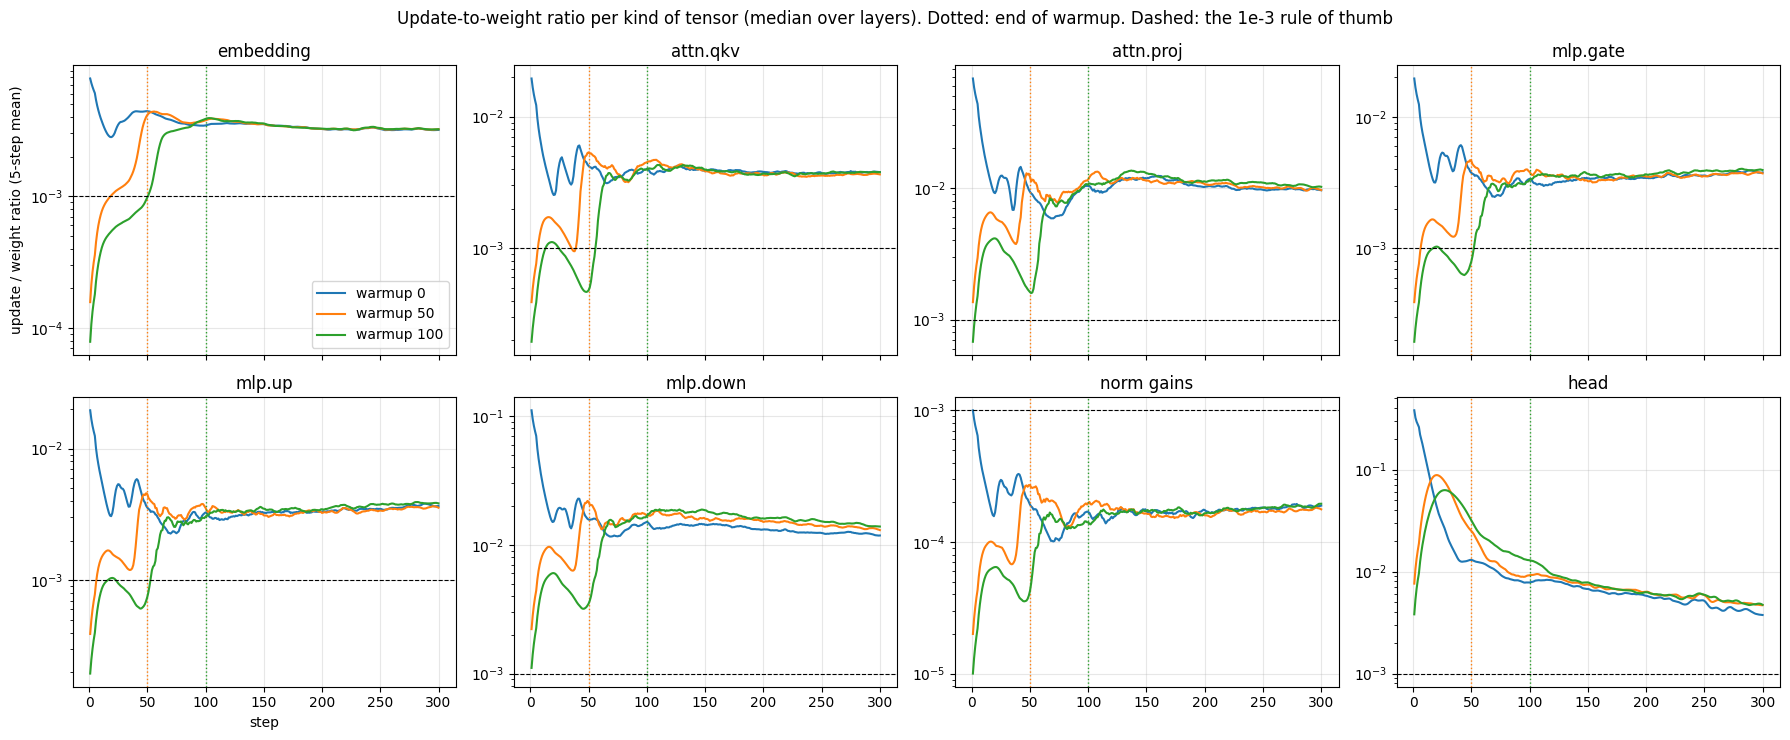

In [20]:
runs3 = {}
for W in (0, 50, 100):
    runs3[W] = train_run(Config(), 1e-3, constant(W), log_ratio=True, label=f"warmup {W}")
    print(f"warmup {W:>3} steps: held-out loss at 100 / 200 / 300 = " + " / ".join(f"{runs3[W]['eval'][s]:.4f}" for s in (100, 200, 300))
          + f"   ({runs3[W]['seconds']:.0f} s)")
names = runs3[0]["ratio_names"]
kinds = ["embedding", "attn.qkv", "attn.proj", "mlp.gate", "mlp.up", "mlp.down", "norm gains", "head"]
def kind_curve(H, kind):
    """Median ratio over all tensors of one kind, per step: (steps,)"""
    cols = [i for i, n in enumerate(names) if tensor_kind(n) == kind]
    return np.median(H["ratio"][:, cols], axis=1)

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), sharex=True)
for ax, kind in zip(axes.flat, kinds):
    for W, c in zip((0, 50, 100), ("C0", "C1", "C2")):
        ax.plot(np.arange(1, STEPS + 1), smooth(kind_curve(runs3[W], kind), 5), color=c, label=f"warmup {W}")
        if W: ax.axvline(W, color=c, ls=":", lw=1)
    ax.axhline(1e-3, color="k", ls="--", lw=0.8)
    ax.set_yscale("log"); ax.set_title(kind); ax.grid(alpha=0.3)
axes[0, 0].legend(); axes[1, 0].set_xlabel("step"); axes[0, 0].set_ylabel("update / weight ratio (5-step mean)")
fig.suptitle("Update-to-weight ratio per kind of tensor (median over layers). Dotted: end of warmup. Dashed: the 1e-3 rule of thumb")
plt.tight_layout()
savefig("update_ratio_per_layer.png")

Where warmup stops changing the update-to-weight ratio (all 51 tensors, summarised per kind)
kind            W  r at step 1  peak of smoothed r at step   within 10% of no-warmup from step  r at step 300
embedding      50     1.57e-04                          58                                  53       3.22e-03
embedding     100     7.85e-05                         107                                 109       3.23e-03
attn.qkv       50     3.89e-04                          55                                 118       3.66e-03
attn.qkv      100     1.94e-04                         136                                 113       3.79e-03
attn.proj      50     1.36e-03                         109                                 122       9.77e-03
attn.proj     100     6.79e-04                         140                                 264       1.02e-02
mlp.gate       50     3.90e-04                          52                                 131       3.75e-03
mlp.gate      100     1.95e

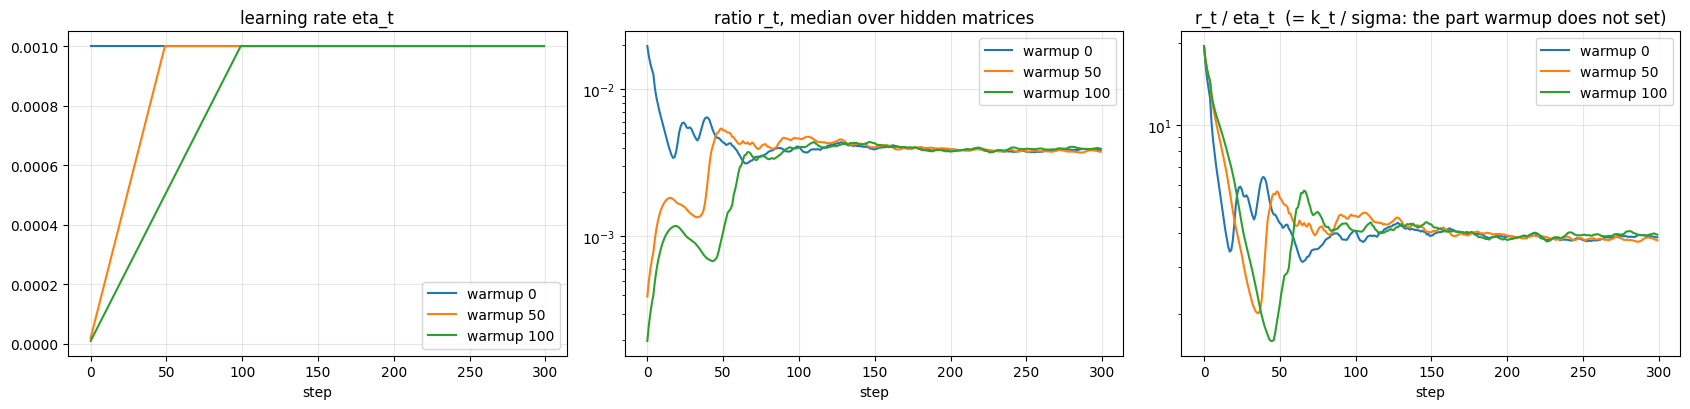

In [21]:
print("Where warmup stops changing the update-to-weight ratio (all 51 tensors, summarised per kind)")
print(f"{'kind':12s} {'W':>4s} {'r at step 1':>12s} {'peak of smoothed r at step':>27s} {'within 10% of no-warmup from step':>35s} {'r at step 300':>14s}")
handoff = {}
for kind in kinds:
    ref = smooth(kind_curve(runs3[0], kind), 10)
    for W in (50, 100):
        r = smooth(kind_curve(runs3[W], kind), 10)
        peak = int(np.argmax(r[:2 * W + 50]) + 1)
        agree = stops_mattering(r / ref - 1, 0.10)
        handoff[(kind, W)] = (peak, agree)
        print(f"{kind:12s} {W:4d} {kind_curve(runs3[W], kind)[0]:12.2e} {peak:27d} {str(agree) if agree else 'never within 300':>35s} {r[-1]:14.2e}")
R["task3_handoff"] = {f"{k}|W={W}": v for (k, W), v in handoff.items()}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for W, c in zip((0, 50, 100), ("C0", "C1", "C2")):
    lr = np.array(runs3[W]["lr"])
    allm = np.median(runs3[W]["ratio"][:, [i for i, n in enumerate(names) if tensor_kind(n) not in ("norm gains", "embedding", "head")]], axis=1)
    axes[0].plot(lr, color=c, label=f"warmup {W}")
    axes[1].plot(smooth(allm, 5), color=c, label=f"warmup {W}")
    axes[2].plot(smooth(allm / lr, 5), color=c, label=f"warmup {W}")
axes[0].set_title("learning rate eta_t"); axes[1].set_title("ratio r_t, median over hidden matrices"); axes[1].set_yscale("log")
axes[2].set_title("r_t / eta_t  (= k_t / sigma: the part warmup does not set)"); axes[2].set_yscale("log")
for a in axes: a.set_xlabel("step"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
savefig("update_ratio_vs_warmup.png")

### Observations (Section 3)

**Answer to the task.** In the three runs (warmup 0, 50 and 100 steps, constant rate after), the ratio of the
hidden matrices (qkv, gate, up) and the norm gains comes within 10% of the no-warmup run's ratio, and stays there,
**from about step 113 to 131, for both warmup lengths**. That is where warmup stops changing it. For warmup 50 it
also peaks right at the end of warmup (steps 52 to 58). For warmup 100 the peak is at 107 to 140, but the peak
criterion picks up meaningless late points (249, 250) for gate, up and norms, whose curves are flat and drift up
slowly. The embedding agrees with the no-warmup run right after warmup ends (53 and 109). **`mlp.down` and the
head never come within 10% in 300 steps**: warmup leaves a lasting effect on them (below).

- **The step-1 predictions held to three digits.** qkv 0.01957 (predicted 0.01960), proj 0.06781 (0.06783), down
  0.1107 (0.1108), norm gains 0.00100 (0.00100), embedding 0.00785 with 1,244 of 50,304 rows in the batch
  (0.00786). The head came out at 0.381 (predicted 0.384), slightly below because some head gradients are comparable
  to $\epsilon$. The lesson's "nineteen times too large" is confirmed: the hidden matrices start at 0.0196 against the
  $10^{-3}$ rule of thumb.
- **With warmup the first ratio is $1/W$ of that**: $3.9\times10^{-4}$ for $W = 50$, $1.9\times10^{-4}$ for
  $W = 100$, exactly the $\eta_1 = \eta/W$ scaling.
- **Without warmup the ratio falls by itself.** It goes from $2\times10^{-2}$ to about $4\times10^{-3}$ in roughly
  20 steps. The right-hand plot, $r_t/\eta_t$, shows why: the gradient-consistency part $k_t/\sigma$ falls from about
  20 to about 4 by step 150 **in all three runs, warmup or not**. Early gradients agree with each other and later ones
  do not, which is the lesson's argument for warmup, measured directly.
- All three runs share a dip near steps 40 to 50 followed by a jump. It appears whatever the schedule, so it is
  something the model goes through at that point, not an effect of warmup.
- **Lasting effect on `mlp.down` and the head.** At step 300, `mlp.down` sits at $1.32$ to $1.39\times10^{-2}$ in the
  warmup runs against $1.2\times10^{-2}$ without warmup, and the head at $4.7\times10^{-3}$ against $3.8\times10^{-3}$.
  These are the tensors with the smallest initial scale (std 0.009 and 0.0026). Without warmup their first steps were
  11% and 38% of their own size, which permanently made $\lVert W\rVert$ (the denominator) larger.
- **Where the ratio settles** (step 300, $\eta = 10^{-3}$): about $3.5$ to $4\times10^{-3}$ for qkv, gate and up,
  $10^{-2}$ for proj, $1.3\times10^{-2}$ for down, $3.2\times10^{-3}$ embedding, $2\times10^{-4}$ norm gains. The hidden
  matrices are 4 to 13 times above the $10^{-3}$ rule of thumb. $10^{-3}$ is the tuned rate for 300-step runs
  (Section 4), and the rule of thumb is meant for long runs.
- Warmup also improved the loss here. Held-out at step 300: 3.257 (no warmup), 3.206 (50), **3.037 (100)**.
  Section 2 shows the same: 3.231 against 3.051 with warmup 100 at $\beta_2 = 0.999$. That is 0.18 to 0.22 nats,
  10 times the seed-to-seed gap.

## 4. Cosine against WSD, both stopped at step 200

### 4a. The schedules and the hand prediction

Both runs are *planned* for 300 steps (20 warmup steps) and *stopped* at step 200. At step 200 (hand values from the
harness section):

| schedule, planned for 300 | $\eta_{200} / \eta_{\text{peak}}$ | what the model has had |
|---|---:|---|
| cosine | 0.355 | 180 steps of gradually falling rate: partly annealed |
| WSD (decay over steps 241 to 300) | 1.000 | no decay at all: still at the full, noisy rate |

**What should happen.** A high learning rate makes fast progress but leaves the weights bouncing around the bottom of
the valley. Lowering the rate lets them settle, and the loss drops quickly as it does: the well-known "annealing
drop" at the end of a WSD run. At step 200 cosine has had part of that drop and WSD none of it, so **cosine should have
the lower loss at step 200.** At step 300 both have fully decayed and should be close.

**But that is not the whole answer to "which model would you keep".** The WSD model at step 200 is unfinished
*on purpose*: since its rate is flat until step 240, its step-160 checkpoint is identical to that of a WSD run
planned for 200 steps. Decaying from that checkpoint over 40 steps gives a *finished* 200-step model at no extra cost
to the main run. Cosine cannot do this: its shape at every step depends on the planned length. Four extra runs make
the comparison fair at equal compute (200 steps):

| run | what it represents |
|---|---|
| cosine planned 300, stopped at 200 | the assignment's cosine model |
| WSD planned 300, stopped at 200 | the assignment's WSD model |
| cosine planned 200 | what cosine gives if you know the length in advance |
| WSD branch: flat until 160, decay 160 to 200 | what WSD gives you from a checkpoint, without knowing the length in advance |
| constant rate + EMA of the weights | the 2026 claim: weight averaging replaces the decay (Section 10 of the lesson) |

**Tuning both sides first.** The lesson's last line: a comparison is only valid when both sides are tuned. So the peak
rate is tuned *separately* for cosine and for WSD, on the planned 300-step run, over
$\{5\times10^{-4}, 10^{-3}, 2\times10^{-3}, 4\times10^{-3}\}$. Then every configuration is run with 3 seeds.

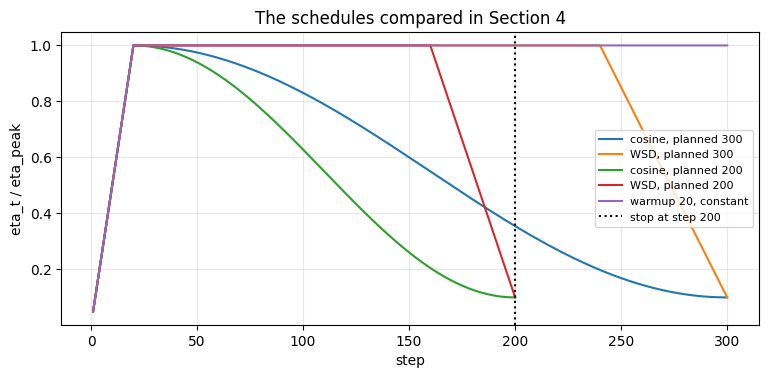

In [22]:
plt.figure(figsize=(9, 3.8))
t = np.arange(1, 301)
for k, s in scheds.items():
    T = 200 if "200" in k else 300
    plt.plot(t[:T], [s(i) for i in t[:T]], label=k)
plt.axvline(200, color="k", ls=":", label="stop at step 200")
plt.xlabel("step"); plt.ylabel("eta_t / eta_peak"); plt.title("The schedules compared in Section 4"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
savefig("schedules.png")

In [23]:
TUNE_LRS = [5e-4, 1e-3, 2e-3, 4e-3]
tune = {}
t0 = time.time()
for sname, s in (("cosine", cosine(20, 300)), ("WSD", wsd(20, 300))):
    for lr in TUNE_LRS:
        tune[(sname, lr)] = train_run(Config(), lr, s, label=f"{sname} lr={lr}")
print(f"[tuning: {time.time() - t0:.0f} s for {len(tune)} runs]\n")
print(f"{'schedule':8s}" + "".join(f"{'lr=' + format(lr, 'g'):>17s}" for lr in TUNE_LRS) + "      (held-out loss at step 200 / step 300)")
best_lr = {}
for sname in ("cosine", "WSD"):
    print(f"{sname:8s}" + "".join(f"  {tune[(sname, lr)]['eval'].get(200, float('nan')):.4f}/{tune[(sname, lr)]['final_eval']:.4f}" for lr in TUNE_LRS))
    best_lr[sname] = min(TUNE_LRS, key=lambda lr: tune[(sname, lr)]["final_eval"] if math.isfinite(tune[(sname, lr)]["final_eval"]) else 99)
    edge = best_lr[sname] in (TUNE_LRS[0], TUNE_LRS[-1])
    print(f"         -> tuned peak lr (best at the planned 300 steps): {best_lr[sname]:g}" + ("   WARNING: at the edge of the grid" if edge else ""))
R["task4_best_lr"] = best_lr

[tuning: 117 s for 8 runs]

schedule        lr=0.0005         lr=0.001         lr=0.002         lr=0.004      (held-out loss at step 200 / step 300)
cosine    3.9897/3.7339  3.9212/3.6295  4.0127/3.7103  3.9791/3.6988
         -> tuned peak lr (best at the planned 300 steps): 0.001
WSD       3.7381/3.2909  3.7424/3.2823  3.9075/3.4390  3.9438/3.5348
         -> tuned peak lr (best at the planned 300 steps): 0.001


In [24]:
SEEDS = (0, 1, 2)
configs4 = {
    "cosine 300, stopped at 200": (best_lr["cosine"], cosine(20, 300), 300, ()),
    "WSD 300, stopped at 200":    (best_lr["WSD"], wsd(20, 300), 300, ()),
    "cosine planned for 200":     (best_lr["cosine"], cosine(20, 200), 200, ()),
    "WSD branch (decay 160-200)": (best_lr["WSD"], wsd(20, 200), 200, ()),
    "constant + EMA of weights":  (best_lr["WSD"], constant(20), 300, (0.9, 0.95, 0.98)),
}
runs4 = {}
t0 = time.time()
for name, (lr, s, T, emas) in configs4.items():
    for seed in SEEDS:
        if seed == 0 and name.startswith(("cosine 300", "WSD 300")):            # identical to the tuning run, reuse it
            runs4[(name, seed)] = tune[("cosine" if name.startswith("cosine") else "WSD", lr)]
        else:
            runs4[(name, seed)] = train_run(Config(), lr, s, steps=T, seed=seed, ema_decays=emas, extra_eval=(160, 200), label=name)
print(f"[{time.time() - t0:.0f} s]\n")

def at(name, step, ema=None):
    vals = [(runs4[(name, s)]["ema_eval"][ema] if ema else runs4[(name, s)]["eval"]).get(step, float("nan")) for s in SEEDS]
    return np.array(vals)

print(f"held-out loss, mean +- std over seeds {SEEDS}, each peak lr tuned for its schedule")
print(f"{'model':42s} {'lr':>7s} {'at step 200':>18s} {'at step 300':>18s}")
table4 = {}
for name, (lr, s, T, emas) in configs4.items():
    a200, a300 = at(name, 200), at(name, 300)
    table4[name] = (a200.mean(), a300.mean() if T == 300 else None)
    print(f"{name:42s} {lr:7.0e} {a200.mean():10.4f} +- {a200.std():.4f} " + (f"{a300.mean():10.4f} +- {a300.std():.4f}" if T == 300 else f"{'(200-step run)':>18s}"))
    for d in emas:
        e200, e300 = at(name, 200, d), at(name, 300, d)
        table4[f"{name}, EMA {d}"] = (e200.mean(), e300.mean())
        print(f"{'   EMA weights, decay ' + str(d) + ' (window ~' + str(round(1 / (1 - d))) + ' steps)':42s} {'':7s} {e200.mean():10.4f} +- {e200.std():.4f} {e300.mean():10.4f} +- {e300.std():.4f}")
d = at("WSD 300, stopped at 200", 200) - at("cosine 300, stopped at 200", 200)
print(f"\npaired difference at step 200, WSD - cosine (same seed = same init and data): {d.mean():+.4f} +- {d.std():.4f} nats  (per seed: {', '.join(f'{x:+.4f}' for x in d)})")
d3 = at("WSD 300, stopped at 200", 300) - at("cosine 300, stopped at 200", 300)
print(f"paired difference at step 300, WSD - cosine: {d3.mean():+.4f} +- {d3.std():.4f} nats")
R["task4_table"] = {k: [float(v[0]), None if v[1] is None else float(v[1])] for k, v in table4.items()}
R["task4_paired_wsd_minus_cos_200"] = [float(d.mean()), float(d.std())]
R["task4_paired_wsd_minus_cos_300"] = [float(d3.mean()), float(d3.std())]

[179 s]

held-out loss, mean +- std over seeds (0, 1, 2), each peak lr tuned for its schedule
model                                           lr        at step 200        at step 300
cosine 300, stopped at 200                   1e-03     3.8628 +- 0.0437     3.5804 +- 0.0392
WSD 300, stopped at 200                      1e-03     3.7022 +- 0.0349     3.2480 +- 0.0307
cosine planned for 200                       1e-03     4.1635 +- 0.0410     (200-step run)
WSD branch (decay 160-200)                   1e-03     3.7616 +- 0.0430     (200-step run)
constant + EMA of weights                    1e-03     3.7022 +- 0.0349     3.2379 +- 0.0225
   EMA weights, decay 0.9 (window ~10 steps)             3.7054 +- 0.0383     3.2053 +- 0.0250
   EMA weights, decay 0.95 (window ~20 steps)             3.7700 +- 0.0401     3.2246 +- 0.0276
   EMA weights, decay 0.98 (window ~50 steps)             4.0487 +- 0.0509     3.3381 +- 0.0318

paired difference at step 200, WSD - cosine (same seed = same init a

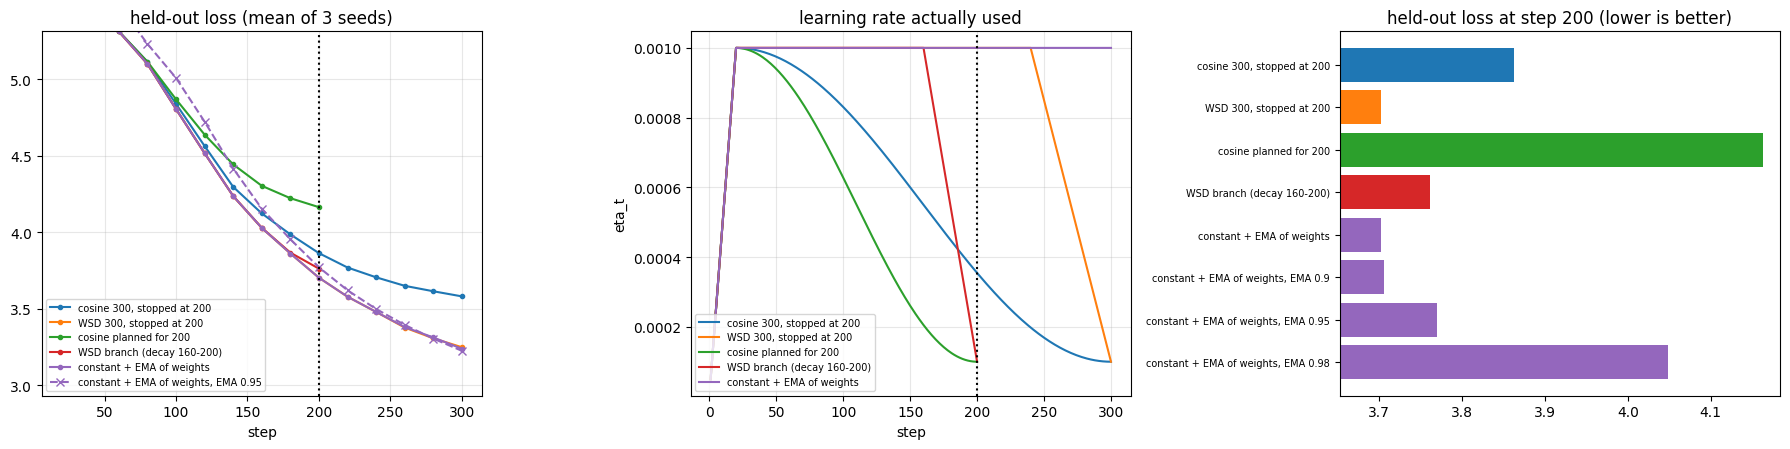

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for i, (name, (lr, s, T, emas)) in enumerate(configs4.items()):
    steps_ = sorted(runs4[(name, 0)]["eval"])
    mean = np.mean([[runs4[(name, sd)]["eval"][st] for st in steps_] for sd in SEEDS], axis=0)
    axes[0].plot(steps_, mean, "o-", ms=3, color=f"C{i}", label=name)
    axes[1].plot(np.arange(1, T + 1), [s(t) * lr for t in range(1, T + 1)], color=f"C{i}", label=name)
    if emas:
        st_e = sorted(runs4[(name, 0)]["ema_eval"][0.95])
        axes[0].plot(st_e, np.mean([[runs4[(name, sd)]["ema_eval"][0.95][st] for st in st_e] for sd in SEEDS], axis=0), "x--", color=f"C{i}", label=name + ", EMA 0.95")
for a in axes[:2]:
    a.axvline(200, color="k", ls=":"); a.set_xlabel("step"); a.grid(alpha=0.3); a.legend(fontsize=7)
axes[0].set_ylim(top=np.mean([runs4[("cosine 300, stopped at 200", sd)]["eval"][60] for sd in SEEDS]))
axes[0].set_title("held-out loss (mean of 3 seeds)"); axes[1].set_title("learning rate actually used"); axes[1].set_ylabel("eta_t")
labels = [k for k in table4]; vals = [table4[k][0] for k in labels]
axes[2].barh(range(len(labels)), vals, color=["C0", "C1", "C2", "C3", "C4", "C4", "C4", "C4"][:len(labels)])
axes[2].set_yticks(range(len(labels))); axes[2].set_yticklabels(labels, fontsize=7); axes[2].invert_yaxis()
axes[2].set_xlim(min(vals) - 0.05, max(vals) + 0.02); axes[2].set_title("held-out loss at step 200 (lower is better)")
plt.tight_layout()
savefig("cosine_vs_wsd.png")

### Observations (Section 4), and which model I would keep

**Answer to the task.** Stopped at step 200 (peak rate tuned separately for each, both came out at $10^{-3}$; 3
seeds):

| model at step 200 | held-out loss |
|---|---:|
| cosine planned for 300 | 3.863 ± 0.044 |
| **WSD planned for 300** | **3.702 ± 0.035** |

Paired by seed, WSD is lower by **0.161 ± 0.014 nats**, with the same sign on all three seeds (−0.179, −0.159,
−0.144). **I would keep the WSD model.** It is better now, and it is a checkpoint from the flat phase, so it can be
trained further at the same rate or decayed later, when the decay is worth having. The cosine model at step 200 is a
half-decayed model from a run that was cut short.

**My prediction was wrong.** I expected cosine to be lower at step 200 because it had been partly annealed. It was
the other way round, and the other runs show why.

- **In this regime, every decay cost loss.** At step 200, the held-out loss is ordered exactly by how much learning
  rate each run had used so far (the sum of $\eta_t/\eta_{\text{peak}}$ over steps 1 to 200):
  cosine planned for 200: area 109, loss 4.164; cosine planned for 300: 145, 3.863; WSD branch decayed over
  160 to 200: 172, 3.762; WSD flat: 190, **3.702**. Even the WSD branch, the "finished" 200-step model, is worse than
  not decaying at all. At step 300, WSD after its 240 to 300 decay (3.248) is no better than the same rate held
  constant (3.238).
- The reason is how undertrained these models are. After 2.5M tokens the loss is still falling by about 0.25 nats
  every 50 steps. Progress is limited by how far the weights can travel, and decaying the rate shortens that
  distance. Annealing pays off when the loss is limited by gradient noise at a high rate, which happens late in long
  runs, not after 300 steps on a fresh model. The lesson's "decay drop" is real, but it needs a longer run than
  this.
- At step 300 the gap widens: **WSD 3.248, cosine 3.580** (paired −0.332 ± 0.010). Cosine starts lowering the rate
  after step 20, so it gives up about 100 peak-rate steps (area 164 against 263).
- **Constant rate plus weight averaging.** A short EMA of the weights (decay 0.9, about 10 steps) gives the best
  model at step 300: 3.205 ± 0.025, against 3.238 for the raw weights, about one standard deviation better. Longer
  windows hurt here (decay 0.98: 4.049 at step 200), because the weights move fast and a 50-step average includes
  stale weights. The 2026 claim (averaging can replace the decay) is consistent with what we see. But the decay itself
  did not help in this regime, so this run cannot test it properly.
- **Tuning check.** On one seed the cosine grid was flat (3.63 to 3.73 over $5\times10^{-4}$ to $4\times10^{-3}$) and
  WSD's best two rates were 3.29 and 3.28. So the cosine deficit is not caused by an untuned rate.

## 5. Learning-rate sweep across widths, and a value for width 4,096

### 5a. Why the best learning rate depends on width

Adam moves every element of a hidden matrix by about $\eta$, *regardless of width* (Section 1d). Now look at what
that does to the layer's output. A layer computes $y_i = \sum_{j=1}^{d} W_{ij} x_j$, a sum over $d$ inputs. If the
update $\Delta W_{ij}$ is about $\eta$ for every $j$ and is correlated with $x$ (which is what a gradient step is),
the change in the output adds up coherently over all $d$ terms:

$$\Delta y_i = \sum_{j=1}^{d} \Delta W_{ij}\, x_j \;\approx\; d \cdot \eta \cdot |x|$$

So with a fixed $\eta$, a model twice as wide changes its activations **twice as much** per step. To keep the change
the same, $\eta$ must be halved: in the standard parameterization (**SP**: one $\eta$ for everything)

$$\eta^*(d) \propto \frac{1}{d}$$

which is the lesson's table (width 256 at $3\times10^{-3}$ down to width 4,096 at $1.9\times10^{-4}$). Hand
prediction for our sweep: if $\eta^*(256) = x$, then $\eta^*(512) \approx x/2$ and $\eta^*(1024) \approx x/4$.

**muP** (maximal update parameterization) builds the $1/d$ into the model, so the same $\eta$ is optimal at
every width. For Adam the rules are:

| tensor | initialisation | learning rate | forward pass |
|---|---|---|---|
| embedding | std constant (0.02) | $\eta$ | unchanged |
| hidden matrices | std $1/\sqrt{\text{fan-in}}$ | $\eta / m$, with $m = d / 256$ | unchanged |
| head (readout) | std $1/d$ | $\eta$ | logits divided by $m$ |
| norm gains | 1 | $\eta$ | unchanged |

At $d = 256$, $m = 1$ and muP is identical to SP, so the two sweeps must agree exactly at width 256.

### 5b. The sweep

Depth 4, head width 64 (so 4, 8 and 16 heads), SwiGLU hidden width $\tfrac83 d$ rounded to 64. 300 steps,
warmup 30, cosine to 10%, AdamW $\beta = (0.9, 0.95)$, weight decay 0.1. Nine learning rates spaced about a factor
2 to 2.5 apart, from $10^{-4}$ to $5\times10^{-2}$. Runs that blow up are stopped early and marked as diverged; once
two rates in a row diverge, larger rates at that width are skipped.

**Locating a minimum between grid points:** a parabola through the best grid point and its two neighbours, in
$\log_{10}\eta$. Its vertex is the estimated $\eta^*$. **Measuring confidence:** the best rate is rerun with two
more seeds to see how large the seed-to-seed noise is compared with the differences between grid points, and the
power-law fit $\eta^* = a\, d^{\,b}$ through three points gets an honest interval (with 3 points and 2 parameters
there is only 1 degree of freedom left, so the interval is wide).

In [26]:
WIDTHS = (256, 512, 1024)
SWEEP_LRS = [1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2, 2e-2, 5e-2]
def width_cfg(d, mup):
    """Config for the width sweep: depth 4, head width 64, muP width multiplier d/256 if mup.

    Example: width_cfg(512, True) -> Config(n_layer=4, n_head=8, d_model=512, d_ff=1408, width_mult=2.0)
    """
    return Config(n_layer=4, n_head=d // 64, d_model=d, d_ff=swiglu_width(d), width_mult=(d / 256 if mup else 1.0))
print(f"{'width':>6} {'heads':>6} {'d_ff':>6} {'weights':>12} {'of which embed+head':>20} {'muP hidden-lr factor 1/m':>26}")
for d in WIDTHS + (4096,):
    c = width_cfg(d, True)
    print(f"{d:6d} {c.n_head:6d} {c.d_ff:6d} {count_params(c):12,d} {2 * c.vocab_size * d:20,d} {1 / c.width_mult:26.4f}")

def sweep(mup, reuse=None):
    """Train every (width, lr) pair for 300 steps; return {(width, lr): held-out loss or nan if diverged}."""
    out, t_start = {}, time.time()
    for d in WIDTHS:
        n_div = 0
        for lr in SWEEP_LRS:
            if reuse is not None and (d, lr) in reuse:
                out[(d, lr)] = reuse[(d, lr)]; continue
            if n_div >= 2:
                out[(d, lr)] = float("nan"); continue
            h = train_run(width_cfg(d, mup), lr, cosine(30, 300), eval_every=100, label=f"d={d} lr={lr}")
            out[(d, lr)] = h["final_eval"]
            n_div = n_div + 1 if (h["diverged"] or not math.isfinite(h["final_eval"])) else 0
            print(f"  {'muP' if mup else 'SP'} width {d:5d}  lr {lr:7.0e}  ->  held-out loss {h['final_eval']:.4f}"
                  + (f"  (diverged at step {h['steps_done']})" if h["diverged"] else "") + f"   [{h['seconds']:.0f} s, total {time.time() - t_start:.0f} s]")
    return out

def print_sweep(res, title):
    print(title)
    print(f"{'width':>6}" + "".join(f"{format(lr, '.0e'):>9s}" for lr in SWEEP_LRS))
    for d in WIDTHS:
        vals = [res[(d, lr)] for lr in SWEEP_LRS]
        best = np.nanargmin(vals)
        print(f"{d:6d}" + "".join(("   *" if i == best else "    ") + (f"{v:5.3f}" if math.isfinite(v) else "  div") for i, v in enumerate(vals)))

 width  heads   d_ff      weights  of which embed+head   muP hidden-lr factor 1/m
   256      4    704   28,969,216           25,755,648                     1.0000
   512      8   1408   64,360,960           51,511,296                     0.5000
  1024     16   2752  153,625,600          103,022,592                     0.2500
  4096     64  10944 1,218,482,176          412,090,368                     0.0625


In [27]:
sp = sweep(mup=False)
print()
print_sweep(sp, "SP: held-out loss after 300 steps (* = best grid point, div = diverged or skipped)")
R["task5_sp_grid"] = {f"{d}|{lr:g}": sp[(d, lr)] for (d, lr) in sp}

  SP width   256  lr   1e-04  ->  held-out loss 6.1844   [10 s, total 10 s]
  SP width   256  lr   2e-04  ->  held-out loss 5.0556   [10 s, total 20 s]
  SP width   256  lr   5e-04  ->  held-out loss 3.9263   [10 s, total 30 s]
  SP width   256  lr   1e-03  ->  held-out loss 3.5588   [10 s, total 41 s]
  SP width   256  lr   2e-03  ->  held-out loss 3.4570   [10 s, total 51 s]
  SP width   256  lr   5e-03  ->  held-out loss 3.6824   [10 s, total 61 s]
  SP width   256  lr   1e-02  ->  held-out loss 3.7842   [10 s, total 71 s]
  SP width   256  lr   2e-02  ->  held-out loss nan  (diverged at step 15)   [0 s, total 72 s]
  SP width   256  lr   5e-02  ->  held-out loss 4.5024   [10 s, total 82 s]
  SP width   512  lr   1e-04  ->  held-out loss 5.1262   [12 s, total 95 s]
  SP width   512  lr   2e-04  ->  held-out loss 4.1742   [12 s, total 109 s]
  SP width   512  lr   5e-04  ->  held-out loss 3.5617   [12 s, total 122 s]
  SP width   512  lr   1e-03  ->  held-out loss 3.5305   [12 s, tot

estimated optimum per width (SP)
  width   256: eta* = 1.91e-03 (parabola), loss 3.4565;  best grid point 0.002;  seed std at that point 0.0924 nats vs gap to 2nd-best grid point 0.1018 nats
  width   512: eta* = 7.60e-04 (parabola), loss 3.5073;  best grid point 0.001;  seed std at that point 0.0817 nats vs gap to 2nd-best grid point 0.0312 nats
  width  1024: eta* = 4.16e-04 (parabola), loss 3.5991;  best grid point 0.0005;  seed std at that point 0.0809 nats vs gap to 2nd-best grid point 0.0818 nats


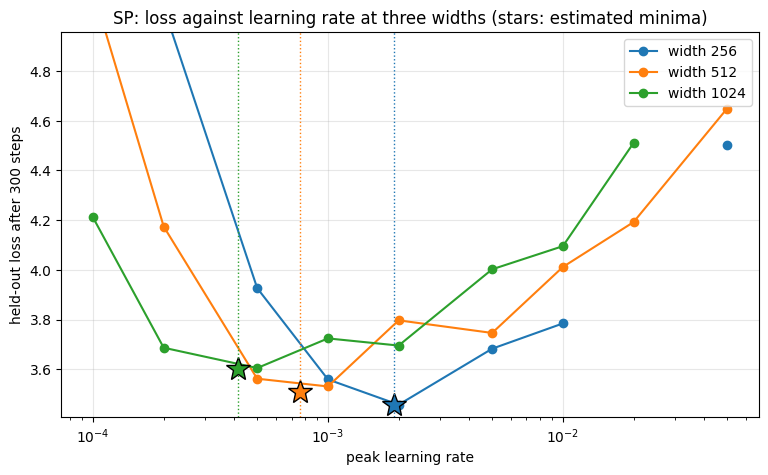

In [28]:
def parabola_min(lrs, losses):
    """Estimated optimum: vertex of a parabola through the best grid point and its neighbours, in log10(lr).

    Returns (lr_star, loss_at_vertex, note). Falls back to the best grid point at the grid edge or if the fit is not convex.
    Example: parabola_min([1e-3, 2e-3, 4e-3], [3.0, 2.9, 3.0]) -> (2e-3, 2.9, 'parabola')
    """
    x = np.log10(np.asarray(lrs, float)); y = np.asarray(losses, float)
    ok = np.isfinite(y); x, y = x[ok], y[ok]
    i = int(np.argmin(y))
    if i == 0 or i == len(y) - 1:
        return 10 ** x[i], y[i], "edge of grid"
    a, b, c = np.polyfit(x[i - 1:i + 2], y[i - 1:i + 2], 2)
    if a <= 0:
        return 10 ** x[i], y[i], "not convex"
    xv = -b / (2 * a)
    return 10 ** xv, a * xv ** 2 + b * xv + c, "parabola"

def minima(res):
    return {d: parabola_min(SWEEP_LRS, [res[(d, lr)] for lr in SWEEP_LRS]) for d in WIDTHS}

sp_min = minima(sp)
print("estimated optimum per width (SP)")
noise = {}
for d in WIDTHS:
    lr_s, l_s, note = sp_min[d]
    vals = [sp[(d, lr)] for lr in SWEEP_LRS]
    best_grid = SWEEP_LRS[int(np.nanargmin(vals))]
    reruns = [train_run(width_cfg(d, False), best_grid, cosine(30, 300), seed=s, eval_every=100)["final_eval"] for s in (1, 2)]
    noise[d] = np.std([np.nanmin(vals)] + reruns)
    srt = sorted(v for v in vals if math.isfinite(v))
    print(f"  width {d:5d}: eta* = {lr_s:.2e} ({note}), loss {l_s:.4f};  best grid point {best_grid:g};  "
          f"seed std at that point {noise[d]:.4f} nats vs gap to 2nd-best grid point {srt[1] - srt[0]:.4f} nats")
R["task5_sp_min"] = {d: [float(v[0]), float(v[1]), v[2]] for d, v in sp_min.items()}
R["task5_sp_seed_std"] = {d: float(v) for d, v in noise.items()}

plt.figure(figsize=(9, 5))
for i, d in enumerate(WIDTHS):
    vals = np.array([sp[(d, lr)] for lr in SWEEP_LRS])
    plt.plot(SWEEP_LRS, vals, "o-", color=f"C{i}", label=f"width {d}")
    plt.plot(sp_min[d][0], sp_min[d][1], "*", ms=18, color=f"C{i}", mec="k")
    plt.axvline(sp_min[d][0], color=f"C{i}", ls=":", lw=1)
plt.xscale("log"); plt.xlabel("peak learning rate"); plt.ylabel("held-out loss after 300 steps")
fin = [v for v in sp.values() if math.isfinite(v)]
plt.ylim(min(fin) - 0.05, min(max(fin), min(fin) + 1.5))
plt.title("SP: loss against learning rate at three widths (stars: estimated minima)"); plt.legend(); plt.grid(alpha=0.3)
savefig("lr_sweep_sp.png")

### 5c. Extrapolating to width 4,096

Fit $\log_{10}\eta^* = \log_{10} a + b \log_{10} d$ through the three minima (a straight line on a log-log plot) and
read it at $d = 4096$, which is 4 times the widest model measured. Three ways to state the answer:

1. **The fitted power law**, with a 95% interval. With 3 points and 2 fitted numbers there is 1 degree of freedom
   left, and the Student-t factor for 1 degree of freedom is 12.7 (against 2.0 for many points), so the interval is
   honest about how little 3 points constrain a slope.
2. **The theory exponent $b = -1$**, anchored at the measured width-1,024 optimum: $\eta^*(4096) = \eta^*(1024)/4$.
3. **The muP sweep** (5d): if its minima line up, the width-256 value transfers directly.

**A caveat that applies to all three:** these optima are for 300-step runs. Short runs prefer larger rates than
long ones (there is no time to benefit from a careful small step), so the value for a full-length 4,096-wide run is
probably lower again.

power-law fit through the 3 SP minima : eta* = 0.804 * d^(-1.099)   (theory: exponent -1)
residual scatter of the 3 points      : 0.057 decades
1) fitted law at d = 4096             : eta* = 8.60e-05, 95% prediction interval 1.6e-06 to 4.7e-03 (a factor 2937 wide)
2) exponent -1 from the width-1024 min: eta* = 4.16e-04 / 4 = 1.04e-04
lesson's table for width 4096         : 1.9e-04 (for its own model and run length)


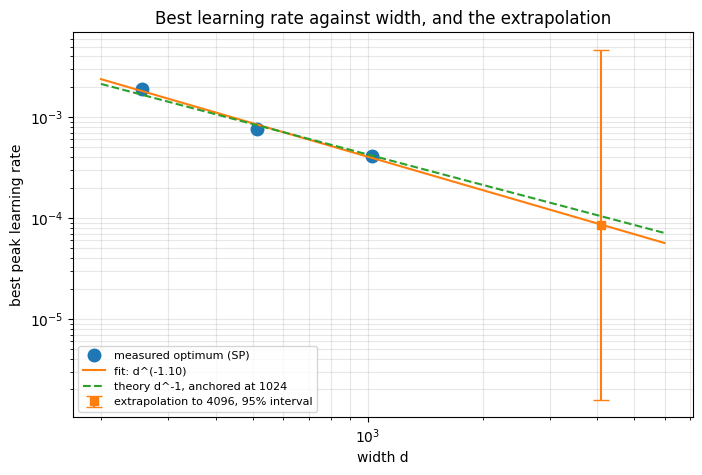

In [29]:
d_arr = np.log10(np.array(WIDTHS, float))
y_arr = np.log10(np.array([sp_min[d][0] for d in WIDTHS]))
b, loga = np.polyfit(d_arr, y_arr, 1)
resid = y_arr - (loga + b * d_arr)
s_res = math.sqrt((resid ** 2).sum() / (len(WIDTHS) - 2)) if len(WIDTHS) > 2 else float("nan")
x0 = math.log10(4096)
se_pred = s_res * math.sqrt(1 + 1 / len(WIDTHS) + (x0 - d_arr.mean()) ** 2 / ((d_arr - d_arr.mean()) ** 2).sum())
T975_DOF1 = 12.706
pred_fit = 10 ** (loga + b * x0)
lo, hi = 10 ** (loga + b * x0 - T975_DOF1 * se_pred), 10 ** (loga + b * x0 + T975_DOF1 * se_pred)
pred_theory = sp_min[1024][0] / 4
print(f"power-law fit through the 3 SP minima : eta* = {10 ** loga:.3g} * d^({b:.3f})   (theory: exponent -1)")
print(f"residual scatter of the 3 points      : {s_res:.3f} decades")
print(f"1) fitted law at d = 4096             : eta* = {pred_fit:.2e}, 95% prediction interval {lo:.1e} to {hi:.1e} (a factor {hi / lo:.0f} wide)")
print(f"2) exponent -1 from the width-1024 min: eta* = {sp_min[1024][0]:.2e} / 4 = {pred_theory:.2e}")
print(f"lesson's table for width 4096         : 1.9e-04 (for its own model and run length)")
R["task5_fit"] = dict(a=float(10 ** loga), b=float(b), pred_4096=float(pred_fit), interval=[float(lo), float(hi)], pred_theory=float(pred_theory))

plt.figure(figsize=(8, 5))
plt.plot(WIDTHS, [sp_min[d][0] for d in WIDTHS], "o", ms=9, label="measured optimum (SP)")
dd = np.array([200, 6000])
plt.plot(dd, 10 ** (loga + b * np.log10(dd)), "-", label=f"fit: d^({b:.2f})")
plt.plot(dd, sp_min[1024][0] * 1024 / dd, "--", label="theory d^-1, anchored at 1024")
plt.errorbar([4096], [pred_fit], yerr=[[pred_fit - lo], [hi - pred_fit]], fmt="s", color="C1", capsize=6, label="extrapolation to 4096, 95% interval")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("width d"); plt.ylabel("best peak learning rate")
plt.title("Best learning rate against width, and the extrapolation"); plt.legend(fontsize=8); plt.grid(alpha=0.3, which="both")
savefig("lr_extrapolation.png")

### 5d. The same sweep under muP

Same grid, same seeds, same data, with muP's hidden learning rate $\eta/m$ and logit multiplier $1/m$. Width 256
is the base width ($m = 1$), where muP and SP are the same model, so those nine runs are reused from the SP sweep.

**Prediction:** the three minima land at about the same $\eta$. If they do, the width-256 optimum is the
muP answer for width 4,096 (with hidden matrices at $\eta/16$), and the confidence is much higher than for the
extrapolated SP slope, because nothing needs extrapolating, only a transfer that the curves show holding.

  muP width   512  lr   1e-04  ->  held-out loss 6.2156   [12 s, total 13 s]
  muP width   512  lr   2e-04  ->  held-out loss 5.2668   [12 s, total 27 s]
  muP width   512  lr   5e-04  ->  held-out loss 4.1123   [12 s, total 40 s]
  muP width   512  lr   1e-03  ->  held-out loss 3.7201   [12 s, total 53 s]
  muP width   512  lr   2e-03  ->  held-out loss 3.5758   [12 s, total 66 s]
  muP width   512  lr   5e-03  ->  held-out loss 3.5874   [12 s, total 80 s]
  muP width   512  lr   1e-02  ->  held-out loss 4.1580   [12 s, total 93 s]
  muP width   512  lr   2e-02  ->  held-out loss 4.1188   [12 s, total 106 s]
  muP width   512  lr   5e-02  ->  held-out loss 4.4604   [12 s, total 119 s]
  muP width  1024  lr   1e-04  ->  held-out loss 6.2311   [19 s, total 141 s]
  muP width  1024  lr   2e-04  ->  held-out loss 5.4379   [19 s, total 162 s]
  muP width  1024  lr   5e-04  ->  held-out loss 4.3311   [19 s, total 184 s]
  muP width  1024  lr   1e-03  ->  held-out loss 3.7690   [19 s, total 

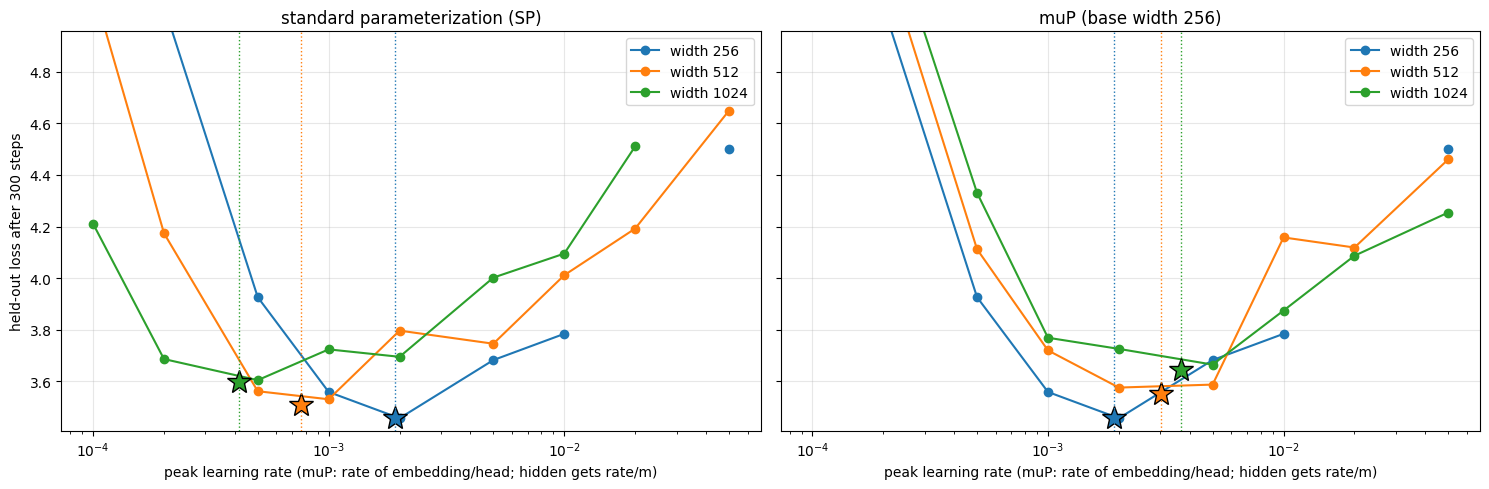

In [30]:
mup = sweep(mup=True, reuse={(256, lr): sp[(256, lr)] for lr in SWEEP_LRS})
print()
print_sweep(mup, "muP: held-out loss after 300 steps (* = best grid point)")
mup_min = minima(mup)
for d in WIDTHS:
    print(f"  width {d:5d}: muP eta* = {mup_min[d][0]:.2e} ({mup_min[d][2]}), loss {mup_min[d][1]:.4f}    |  SP eta* = {sp_min[d][0]:.2e}, loss {sp_min[d][1]:.4f}")
spread_sp = max(sp_min[d][0] for d in WIDTHS) / min(sp_min[d][0] for d in WIDTHS)
spread_mup = max(mup_min[d][0] for d in WIDTHS) / min(mup_min[d][0] for d in WIDTHS)
print(f"\nspread of the optimum across widths 256-1024: SP {spread_sp:.1f}x, muP {spread_mup:.1f}x (1.0x = perfect transfer)")
R["task5_mup_grid"] = {f"{d}|{lr:g}": mup[(d, lr)] for (d, lr) in mup}
R["task5_mup_min"] = {d: [float(v[0]), float(v[1]), v[2]] for d, v in mup_min.items()}
R["task5_spread"] = dict(sp=float(spread_sp), mup=float(spread_mup))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
fin = [v for v in list(sp.values()) + list(mup.values()) if math.isfinite(v)]
for ax, res, mins, title in ((axes[0], sp, sp_min, "standard parameterization (SP)"), (axes[1], mup, mup_min, "muP (base width 256)")):
    for i, d in enumerate(WIDTHS):
        ax.plot(SWEEP_LRS, [res[(d, lr)] for lr in SWEEP_LRS], "o-", color=f"C{i}", label=f"width {d}")
        ax.plot(mins[d][0], mins[d][1], "*", ms=18, color=f"C{i}", mec="k"); ax.axvline(mins[d][0], color=f"C{i}", ls=":", lw=1)
    ax.set_xscale("log"); ax.set_xlabel("peak learning rate (muP: rate of embedding/head; hidden gets rate/m)"); ax.set_title(title)
    ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("held-out loss after 300 steps"); axes[0].set_ylim(min(fin) - 0.05, min(max(fin), min(fin) + 1.5))
plt.tight_layout()
savefig("lr_sweep_sp_vs_mup.png")

### Observations (Section 5): the value for width 4,096 and how confident I am

**Answer to the task.** SP minima (parabola vertex): **$1.91\times10^{-3}$ at width 256, $7.60\times10^{-4}$ at 512,
$4.16\times10^{-4}$ at 1,024**. The fitted exponent is **−1.10**, close to the theoretical −1. **The value I would
use at width 4,096 is $1\times10^{-4}$**: the fitted law gives $8.6\times10^{-5}$ and the −1 rule anchored at width
1,024 gives $1.04\times10^{-4}$. **Confidence: low to moderate.** I trust it to within a factor of 2 (about
$5\times10^{-5}$ to $2\times10^{-4}$) *for a 300-step run of this model family*. For a full-length run I would treat
it as the centre of a 3-point check ($3\times10^{-5}$, $10^{-4}$, $3\times10^{-4}$), not as the answer.

Why only low to moderate:

- **Seed noise is as large as the differences being measured.** The best grid point rerun with 3 seeds has a standard
  deviation of 0.08 to 0.09 nats, while neighbouring grid points differ by 0.03 to 0.10. Each minimum is uncertain by
  about one grid step (a factor of 2). The bumps in the curves are noise of that size, for example 512 at
  $2\times10^{-3}$ (3.80) being worse than at $5\times10^{-3}$ (3.75).
- **Three points, one degree of freedom.** The formal 95% interval at 4,096 runs from $1.6\times10^{-6}$ to
  $4.7\times10^{-3}$, a factor of 2,937. The point estimate is believable mainly because the slope agrees with theory,
  not because three points pin it down.
- **4 times extrapolation, and short runs.** Short runs favour larger rates, so the full-run optimum is probably lower.
- The "diverged" mark at width 256, $2\times10^{-2}$, is my early-stop rule (loss above 15 at step 15). The same width
  at $5\times10^{-2}$ survived the spike and finished at 4.50, so that cell is a single spike, not proof that the
  rate is unusable.

**muP (5d).** The minima move much less: $1.91\times10^{-3}$, $3.02\times10^{-3}$, $3.66\times10^{-3}$, a spread of
**1.9 times across widths against 4.6 times for SP**. They are not perfectly aligned. They drift *upwards* by about
1.4 times per doubling of width, within the ±2 times noise of each minimum. The drift may also come from my minimal
muP (embedding rate and weight decay not adjusted with width, 300-step runs). muP did not improve the model:
best losses 3.553 and 3.642 at widths 512 and 1,024, against 3.507 and 3.599 for SP, within noise. That is the lesson's
point: muP makes the small sweep valid for the large model, it does not make the model better.

**The two methods agree on the answer.** If muP transfer holds, the base rate at 4,096 is about $2$ to
$4\times10^{-3}$, and the hidden matrices get it divided by $m = 16$: about $1.2$ to $2.3\times10^{-4}$. The SP
extrapolation gives $1\times10^{-4}$ for all weights. The two estimates were reached independently and differ by
about a factor of 2.

One more surprise: at 300 steps the wider models are *worse* at their own optimum (3.46, 3.51, 3.60). 2.5M tokens are
not enough for the extra width to pay off, and most of the added weights are in the embedding and head.

## Limits of this work

- **Short runs, small models.** Every training run is 300 steps (2.5M tokens) on models of 29M to 154M weights,
  67% to 89% of them in the embedding and head. The loss is still falling fast at step 300, so the schedule
  conclusions (Section 4: no decay ever helped) describe this undertrained regime and should not be read as a general
  ranking of cosine and WSD. Effects that need long runs, like the $1/(\eta\lambda)$ averaging timescale of AdamW
  (33,000 steps in the lesson's example), cannot appear here.
- **Few seeds, and the noise is large.** Seed-to-seed spread is 0.02 to 0.04 nats in Sections 2 to 4 and 0.08 to
  0.09 nats at the sweep optima in Section 5, as large as the gaps between neighbouring grid points. Section 4 uses 3
  seeds per configuration but tunes the peak rate on one seed. Section 5 uses one seed per grid point plus 2 extra
  seeds at each width's best point. Sections 2 and 3 use one seed plus one noise-floor run.
- **Width 4,096 is extrapolated, not measured**, from 3 points, 4 times beyond the widest model.
- **Thresholds are my choices:** 1% and 10% for "stops mattering"; twice the mean seed gap as the noise band in 2c;
  the 10%-agreement rule and the peak of a 10-step mean for the warmup hand-off (the peak criterion gave meaningless
  values for flat curves); loss above 15 as "diverged"; a three-point parabola for the minima.
- **muP is a minimal version:** hidden rate $\eta/m$, readout multiplier $1/m$, head width fixed at 64. The embedding
  rate and the weight decay are not rescaled with width.
- **Not reproduced:** the lesson's $0.281\eta$ step for noisy gradients (we measure 0.183 at steady state) and the
  100-times L2 gap (we measure 17 times). Both are explained above, but I cannot tell what setting the lesson used.
- **Not covered:** 8-bit Adam (bitsandbytes not installed) and Muon. Neither is part of the assignment.

In [31]:
R["notebook_minutes"] = (time.time() - NOTEBOOK_T0) / 60
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
print(json.dumps(_clean(R), indent=1))

{
 "n_params_default": 49255296,
 "sec_per_300_step_run_default": 19.940969944000244,
 "task1_maxdiff_w_Adam_float64": 0.0,
 "task1_maxdiff_w_Adam_float32": 1.3233542928148267e-08,
 "task1_maxdiff_w_AdamW_float64": 0.0,
 "task1_maxdiff_w_AdamW_float32": 3.13886975300548e-08,
 "task1_real_matrix_max_w_diff": 1.4901161193847656e-08,
 "noisy_step_over_lr_steady": 0.1830320374674635,
 "noisy_step_over_lr_first100": 0.21606316910620207,
 "l2_B_over_A": 17.083555085377085,
 "adamw_B_over_A": 1.0000000044583714,
 "adamw_bytes_per_weight": 16.0,
 "bias_within1pct_b2_0.999": 3925,
 "bias_within1pct_b2_0.99": 391,
 "bias_within1pct_b2_0.95": 76,
 "task2_real_stops_mattering[beta2=0.999, uncorrected]": null,
 "task2_real_gap300[beta2=0.999, uncorrected]": 0.9800943732261658,
 "task2_real_stops_mattering[beta2=0.95, uncorrected]": 63,
 "task2_real_gap300[beta2=0.95, uncorrected]": 0.023815155029296875,
 "task2_real_stops_mattering[beta2=0.999, uncorrected, warmup 100]": null,
 "task2_real_gap300[b

## Release the Colab runtime

A Colab runtime keeps billing compute units for as long as it stays connected, whether or not anything runs.
(Once, in the middle of this course, I left one connected and lost about 30% of a month's credits for nothing.
Real LLM training has the same failure at a far larger scale: idle GPUs reserved by a job that has stopped
making progress.) The cell below gives the runtime back as soon as the notebook has finished.

**After it runs, save the notebook in VS Code (Ctrl+S)** so the outputs are kept; the PNGs written on the Colab
disk disappear with the runtime, but every plot is also embedded in the notebook.

In [32]:
AUTO_DISCONNECT = True
if AUTO_DISCONNECT:
    try:
        from google.colab import runtime
        print("Releasing the Colab runtime now. Save the notebook in VS Code (Ctrl+S) to keep these outputs.")
        runtime.unassign()
    except Exception as e:
        print(f"Could not release the runtime automatically ({e}). Disconnect it by hand in Colab.")

Releasing the Colab runtime now. Save the notebook in VS Code (Ctrl+S) to keep these outputs.
